# ✍️ Lab 05 (Part 2 of 2): Can an LLM Judge Replace Your Analysts? 🔬

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/05-generative-outputs-part-2-lab.ipynb)

⏱️ ~35 min core (Tasks 9–12) · +45 min for the five challenges

**Previously, in Part 1:**<br>
① Claims, completeness and recomputation each caught errors the others missed.<br>
② A binary judge matched the expert on 22 of 23 verdicts. The VP: *"90% agreement. Retire the analysts."*<br>
③ Now: is that number real?

**How this lab works**
- ▶️ **Run**: <kbd>Shift</kbd>+<kbd>Enter</kbd>; collapsed 🧰 cells just need running.
- ✋ **Your turn**: replace the `...`; a card grades it.
- ❓ **Quick check**: pick an answer, then run.
- 🔑 **Key takeaway**: the line to remember.

▶️ **Run** the next four cells: 📦 install (real judge only) · ⚙️ config (set `PROVIDER` here too) · 🎨 lab kit · 🧰 catch-up (rebuilds Part 1).

In [ ]:
%%capture
# Only needed for a REAL judge (PROVIDER = "openai" or "anthropic").
# pandas, numpy, scikit-learn, matplotlib and pydantic are preinstalled in Colab.
!pip install -U openai anthropic

In [ ]:
import json                      # source data -> judge prompt
import re                        # claim extraction and text parsing
import hashlib                   # deterministic "noise" for the simulated judges
from collections import defaultdict
from typing import Literal

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field          # the judge's verdict schema (structured output)
from sklearn.metrics import cohen_kappa_score  # agreement beyond chance

# ── Configuration: the ONLY place model names live ─────────────────────────────
PROVIDER = "mock"                              # "mock" (offline, default) | "openai" | "anthropic"
OPENAI_JUDGE_MODEL = "gpt-6-luna"              # stronger judge: "gpt-6.1-sol"
ANTHROPIC_JUDGE_MODEL = "claude-haiku-5-5"     # stronger judge: "claude-sonnet-5-5"
SEED = 7                                       # fixes the synthetic data (a real judge is never deterministic)

pd.set_option("display.width", 150)
pd.set_option("display.max_colwidth", 70)
print(f"✅ Imports OK · PROVIDER = {PROVIDER!r}")

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v2 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
#   check(label, got, expected, hint=, success=) -> grades a ✋ Your turn exercise: ✅ / ❌ + hint / ⏳ (still `...`)
#   quiz(label, choice, correct, why, wrong=)    -> grades a ❓ dropdown answer and explains it
#   todo(x)                                      -> True while an exercise blank is still `...`
#   scoreboard()                                 -> your exercise + quiz score so far, and what to revisit
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


# ----------------------------------------------------------------- interactive: exercises, quizzes, score
_SCORE = {}   # label -> (kind, status) where status is "pass" | "fail" | "todo"


class _Graded(int):
    """check()/quiz() result: works like True/False (if, ==, sum) but prints nothing as a cell's last line."""
    def __repr__(self):
        return "True" if self else "False"

    def _ipython_display_(self):
        pass


def todo(x):
    """True while an exercise blank is still `...` (or None)."""
    return x is Ellipsis or x is None


def _card(icon, label, headline, body, accent, tint):
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:10px 16px;margin:8px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {_md(label)}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:3px 0 4px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def _same(got, expected, tol):
    try:
        import numpy as _np
        if isinstance(got, (_np.generic,)):
            got = got.item()
        if isinstance(expected, (_np.generic,)):
            expected = expected.item()
    except ImportError:
        pass
    if isinstance(expected, bool) or isinstance(got, bool):
        return got == expected
    if isinstance(expected, (int, float)) and isinstance(got, (int, float)):
        return abs(float(got) - float(expected)) <= tol * max(1.0, abs(float(expected)))
    if isinstance(expected, str) and isinstance(got, str):
        return got.strip().lower() == expected.strip().lower()
    if isinstance(expected, (set, frozenset)) or isinstance(got, (set, frozenset)):
        try:
            return set(got) == set(expected)
        except TypeError:
            return False
    return got == expected


def check(label, got, expected=None, *, ok=None, tol=1e-6, hint="", success="", reveal=False):
    """Grade a ✋ Your turn exercise.

    got:      the learner's answer (still `...` = not attempted yet: shows ⏳, never an error)
    expected: the reference answer (compared with tolerance for numbers, case-insensitively for strings)
    ok:       pass a bool instead of `expected` for custom rules (e.g. ok=my_case_fools_the_grader)
    reveal:   show the expected answer on a wrong attempt (default False: the hint teaches, the answer spoils)
    """
    if todo(got):
        _SCORE[label] = ("exercise", "todo")
        _card("⏳", f"Your turn · {label}", "Not attempted yet",
              "Replace the `...` above with your answer and re-run this cell. "
              "The lab keeps going with the reference answer, so later cells still work.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    try:
        passed = bool(ok) if ok is not None else _same(got, expected, tol)
    except Exception:
        passed = False
    _SCORE[label] = ("exercise", "pass" if passed else "fail")
    if passed:
        _card("✅", f"Correct · {label}", success or "Nice. That matches the reference.", "", "#0ca30c", "#ecf8ec")
    else:
        shown = f"You got `{got!r}`" + (f"; expected `{expected!r}`" if reveal and ok is None and expected is not None else "") + "."
        _card("❌", f"Not yet · {label}", shown, (f"💡 Hint: {hint}" if hint else "Re-read the step above and try again."),
              "#d03b3b", "#fcefef")
    return _Graded(passed)


def quiz(label, choice, correct, why, wrong=None):
    """Grade a ❓ dropdown answer. choice: the @param string, e.g. "B) The average hides it".
    correct: the letter ("B"). why: the explanation (shown once answered). wrong: {letter: feedback for that pick}."""
    pick = str(choice).strip()[:1].upper()
    if not pick.isalpha():
        _SCORE[label] = ("quiz", "todo")
        _card("❓", f"Quick check · {label}", "Pick an answer in the dropdown, then run this cell.",
              "Commit before you scroll: a guess you wrote down is what makes the next result stick.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    passed = pick == str(correct).strip()[:1].upper()
    _SCORE[label] = ("quiz", "pass" if passed else "fail")
    extra = (wrong or {}).get(pick, "")
    if passed:
        _card("✅", f"Quick check · {label}", f"Right: {correct}.", why, "#0ca30c", "#ecf8ec")
    else:
        _card("🔁", f"Quick check · {label}", f"Not quite: you picked {pick}, the answer is {correct}.",
              (extra + "\n" if extra else "") + why, "#ec835a", "#fdf1ec")
    return _Graded(passed)


def scoreboard():
    """Your score on every ✋ exercise and ❓ quick check you've run, plus what to revisit."""
    ex = [s for k, s in _SCORE.values() if k == "exercise"]
    qz = [s for k, s in _SCORE.values() if k == "quiz"]
    redo = [lbl for lbl, (_, s) in _SCORE.items() if s != "pass"]
    tiles([
        ("✋ Exercises solved", f"{ex.count('pass')}/{len(ex)}", f"{ex.count('todo')} not attempted",
         "good" if ex and ex.count("pass") == len(ex) else "warning"),
        ("❓ Quick checks right", f"{qz.count('pass')}/{len(qz)}", f"{qz.count('todo')} unanswered",
         "good" if qz and qz.count("pass") == len(qz) else "warning"),
    ])
    if redo:
        insight("Worth a second pass", "\n".join(f"• {r}" for r in redo), kind="warning")
    elif _SCORE:
        insight("Clean sweep", "Every exercise and quick check correct. Try the 🏆 challenges next.", kind="insight")


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), check(), quiz(), scoreboard()")

In [ ]:
# @title 🧰 Catch-up: rebuild what Part 1 computed (hidden · 795 lines)
import io as _io, sys as _sys
_real_out, _real_insight, _real_tiles = _sys.stdout, insight, tiles
_sys.stdout, insight, tiles = _io.StringIO(), (lambda *a, **k: None), (lambda *a, **k: None)

# ── from Part 1 (Task cell 8) ────────────────────────────────────────
# ──────────────────────────────────────────────────────────────
# Synthetic financial analysis evaluation dataset
# Each entry represents one quarterly summary generated by an LLM.
#
# STRUCTURE OF EACH ENTRY:
#   - source_data: The ACTUAL numbers (our ground truth)
#   - generated_summary: What the LLM wrote (what we're checking)
#   - key_facts: Facts that SHOULD appear (for completeness scoring)
#   - numeric_claims: Specific numbers to verify (stated vs actual)
#   - human_quality_score: Expert rating for comparison to our automated scores
# ──────────────────────────────────────────────────────────────

financial_dataset = [
    {
        "id": 1,
        "company": "TechFlow Inc.",
        "quarter": "Q3 2025",
        "source_data": {
            "revenue": 142_000_000,
            "revenue_prev_quarter": 128_000_000,
            "revenue_prev_year": 118_000_000,
            "operating_expenses": 98_000_000,
            "net_income": 31_000_000,
            "net_income_prev_quarter": 27_000_000,
            "gross_margin_pct": 45.2,
            "operating_margin_pct": 31.0,
            "eps": 2.15,
            "eps_prev_quarter": 1.88,
            "total_debt": 85_000_000,
            "cash_on_hand": 210_000_000,
            "headcount": 3_200,
            "guidance_next_quarter_revenue_low": 148_000_000,
            "guidance_next_quarter_revenue_high": 155_000_000,
            "notable_events": ["Acquired DataSync Corp for $45M", "Launched CloudEdge platform"]
        },
        # This summary is HIGH QUALITY — accurate, complete, well-framed
        "generated_summary": "TechFlow Inc. reported strong Q3 2025 results with revenue of $142M, up 10.9% quarter-over-quarter and 20.3% year-over-year. Net income reached $31M with EPS of $2.15, representing 14.4% growth over Q2. The company maintains a healthy balance sheet with $210M in cash against $85M in total debt. Operating margin was 31.0% with gross margins at 45.2%. During the quarter, TechFlow acquired DataSync Corp for $45M and launched the CloudEdge platform. Management guided Q4 revenue to $148M-$155M, signaling continued momentum.",
        "key_facts": [
            "Revenue of $142M",
            "Quarter-over-quarter revenue growth",
            "Year-over-year revenue growth",
            "Net income of $31M",
            "EPS of $2.15",
            "Cash position of $210M",
            "Debt position of $85M",
            "Acquisition of DataSync Corp",
            "Launch of CloudEdge platform",
            "Q4 revenue guidance range"
        ],
        "numeric_claims": {
            "revenue": {"stated": 142_000_000, "actual": 142_000_000},
            "qoq_growth_pct": {"stated": 10.9, "actual": 10.94},
            "yoy_growth_pct": {"stated": 20.3, "actual": 20.34},
            "eps": {"stated": 2.15, "actual": 2.15},
            "eps_growth_pct": {"stated": 14.4, "actual": 14.36},
            "net_income": {"stated": 31_000_000, "actual": 31_000_000}
        },
        "human_quality_score": 5  # Expert says: excellent summary
    },
    {
        "id": 2,
        "company": "GreenLeaf Energy",
        "quarter": "Q3 2025",
        "source_data": {
            "revenue": 89_000_000,
            "revenue_prev_quarter": 94_000_000,
            "revenue_prev_year": 82_000_000,
            "operating_expenses": 78_000_000,
            "net_income": 4_500_000,
            "net_income_prev_quarter": 11_000_000,
            "gross_margin_pct": 28.1,
            "operating_margin_pct": 12.4,
            "eps": 0.38,
            "eps_prev_quarter": 0.92,
            "total_debt": 220_000_000,
            "cash_on_hand": 45_000_000,
            "headcount": 1_800,
            "guidance_next_quarter_revenue_low": 91_000_000,
            "guidance_next_quarter_revenue_high": 97_000_000,
            "notable_events": ["Debt covenant waiver obtained from lenders", "CEO transition announced"]
        },
        # ⚠️ This summary is MISLEADING — everything stated is true,
        # but it OMITS critical negative information (declining revenue,
        # plummeting income, debt covenant waiver, CEO leaving)
        "generated_summary": "GreenLeaf Energy posted Q3 2025 revenue of $89M, growing 8.5% year-over-year. Operating margin remained healthy at 12.4%. EPS came in at $0.38. The company has $45M in cash and continues to invest in renewable infrastructure expansion. Management expects Q4 revenue between $91M and $97M, reflecting confidence in their growth strategy.",
        "key_facts": [
            "Revenue of $89M",
            "Revenue declined quarter-over-quarter",
            "Year-over-year revenue growth",
            "Significant net income decline",
            "EPS of $0.38 (sharp drop from $0.92)",
            "High debt level of $220M",
            "Low cash position of $45M relative to debt",
            "Debt covenant waiver obtained",
            "CEO transition announced",
            "Q4 revenue guidance range"
        ],
        "numeric_claims": {
            "revenue": {"stated": 89_000_000, "actual": 89_000_000},
            "yoy_growth_pct": {"stated": 8.5, "actual": 8.54},
            "operating_margin_pct": {"stated": 12.4, "actual": 12.4},
            "eps": {"stated": 0.38, "actual": 0.38}
        },
        "human_quality_score": 2  # Expert says: dangerously misleading
    },
    {
        "id": 3,
        "company": "MedVault Health",
        "quarter": "Q3 2025",
        "source_data": {
            "revenue": 210_000_000,
            "revenue_prev_quarter": 198_000_000,
            "revenue_prev_year": 175_000_000,
            "operating_expenses": 165_000_000,
            "net_income": 33_000_000,
            "net_income_prev_quarter": 29_000_000,
            "gross_margin_pct": 52.8,
            "operating_margin_pct": 21.4,
            "eps": 1.72,
            "eps_prev_quarter": 1.51,
            "total_debt": 150_000_000,
            "cash_on_hand": 320_000_000,
            "headcount": 5_400,
            "guidance_next_quarter_revenue_low": 218_000_000,
            "guidance_next_quarter_revenue_high": 225_000_000,
            "notable_events": ["FDA approval for DiagnostiQ AI platform", "Expanded into 3 new European markets"]
        },
        # ⚠️ This summary has a NUMERIC ERROR — states 25% YoY growth
        # but the actual calculation is (210-175)/175 = 20.0%
        "generated_summary": "MedVault Health delivered solid Q3 2025 results. Revenue hit $210M, up 6.1% from Q2 and 25% year-over-year — a strong acceleration driven by the new DiagnostiQ AI platform which received FDA approval during the quarter. Net income was $33M with EPS of $1.72. Gross margins expanded to 52.8%, among the best in the health-tech sector. The company expanded into 3 new European markets and holds a fortress balance sheet with $320M in cash versus $150M in debt. Operating expenses rose to $165M reflecting investment in European expansion. Q4 guidance of $218M-$225M suggests management expects mid-single-digit sequential growth.",
        "key_facts": [
            "Revenue of $210M",
            "Quarter-over-quarter revenue growth",
            "Year-over-year revenue growth",
            "Net income of $33M",
            "EPS of $1.72",
            "Gross margin of 52.8%",
            "FDA approval for DiagnostiQ AI",
            "European market expansion",
            "Cash position of $320M",
            "Debt of $150M",
            "Q4 revenue guidance range"
        ],
        "numeric_claims": {
            "revenue": {"stated": 210_000_000, "actual": 210_000_000},
            "qoq_growth_pct": {"stated": 6.1, "actual": 6.06},
            "yoy_growth_pct": {"stated": 25.0, "actual": 20.0},  # <-- THE ERROR: 25% vs 20%
            "eps": {"stated": 1.72, "actual": 1.72},
            "gross_margin_pct": {"stated": 52.8, "actual": 52.8},
            "net_income": {"stated": 33_000_000, "actual": 33_000_000}
        },
        "human_quality_score": 3  # Expert says: good but has a numeric error
    },
    {
        "id": 4,
        "company": "UrbanLogix",
        "quarter": "Q3 2025",
        "source_data": {
            "revenue": 67_000_000,
            "revenue_prev_quarter": 71_000_000,
            "revenue_prev_year": 63_000_000,
            "operating_expenses": 72_000_000,
            "net_income": -8_500_000,
            "net_income_prev_quarter": -3_200_000,
            "gross_margin_pct": 18.7,
            "operating_margin_pct": -7.5,
            "eps": -0.62,
            "eps_prev_quarter": -0.23,
            "total_debt": 180_000_000,
            "cash_on_hand": 52_000_000,
            "headcount": 2_100,
            "guidance_next_quarter_revenue_low": 70_000_000,
            "guidance_next_quarter_revenue_high": 75_000_000,
            "notable_events": ["Restructuring plan announced — 15% workforce reduction", "Entered partnership with CityGrid for smart delivery"]
        },
        # ⚠️ This summary SPINS negative news positively —
        # calls widening losses "strategic investments" and omits the layoffs
        "generated_summary": "UrbanLogix reported Q3 2025 revenue of $67M, up 6.3% year-over-year, demonstrating resilience in the logistics space. While operating expenses of $72M exceeded revenue, the company's strategic investments are positioning it for long-term growth. EPS was -$0.62. The company announced an exciting partnership with CityGrid for smart delivery solutions and has $52M in cash to fund operations. Management guided Q4 revenue to $70M-$75M.",
        "key_facts": [
            "Revenue of $67M",
            "Revenue declined quarter-over-quarter",
            "Year-over-year revenue growth",
            "Net loss of $8.5M (widening losses)",
            "Negative operating margin of -7.5%",
            "EPS of -$0.62 (worsening from -$0.23)",
            "High debt of $180M vs $52M cash",
            "15% workforce restructuring",
            "CityGrid partnership",
            "Q4 revenue guidance range"
        ],
        "numeric_claims": {
            "revenue": {"stated": 67_000_000, "actual": 67_000_000},
            "yoy_growth_pct": {"stated": 6.3, "actual": 6.35},
            "operating_expenses": {"stated": 72_000_000, "actual": 72_000_000},
            "eps": {"stated": -0.62, "actual": -0.62}
        },
        "human_quality_score": 2  # Expert says: misleading positive spin
    },
    {
        "id": 5,
        "company": "NexaPay Financial",
        "quarter": "Q3 2025",
        "source_data": {
            "revenue": 325_000_000,
            "revenue_prev_quarter": 310_000_000,
            "revenue_prev_year": 280_000_000,
            "operating_expenses": 245_000_000,
            "net_income": 58_000_000,
            "net_income_prev_quarter": 52_000_000,
            "gross_margin_pct": 61.3,
            "operating_margin_pct": 24.6,
            "eps": 3.42,
            "eps_prev_quarter": 3.07,
            "total_debt": 120_000_000,
            "cash_on_hand": 480_000_000,
            "headcount": 8_200,
            "guidance_next_quarter_revenue_low": 335_000_000,
            "guidance_next_quarter_revenue_high": 345_000_000,
            "notable_events": ["Launched instant cross-border payments in 12 new countries", "Regulatory approval for crypto custody services"]
        },
        # ⚠️ This summary has FABRICATED details — says 15 countries
        # (actual: 12) and EPS growth of 22% (actual: ~11.4%)
        "generated_summary": "NexaPay Financial posted exceptional Q3 2025 results with revenue of $325M, up 4.8% sequentially and 16.1% year-over-year. Net income surged to $58M, driving EPS to $3.42 — a 22% increase versus Q2. Gross margins of 61.3% and operating margins of 24.6% reflect excellent unit economics. The company launched instant cross-border payments in 15 new countries and received regulatory approval for crypto custody services. With $480M in cash and only $120M in debt, NexaPay has significant capacity for M&A. Q4 guidance of $335M-$345M represents 3-6% sequential growth. One risk to watch: operating expenses of $245M grew faster than revenue on a percentage basis.",
        "key_facts": [
            "Revenue of $325M",
            "Quarter-over-quarter revenue growth",
            "Year-over-year revenue growth",
            "Net income of $58M",
            "EPS of $3.42",
            "Gross margin of 61.3%",
            "Operating margin of 24.6%",
            "Cross-border payments expansion",
            "Crypto custody regulatory approval",
            "Strong cash position ($480M vs $120M debt)",
            "Q4 revenue guidance range"
        ],
        "numeric_claims": {
            "revenue": {"stated": 325_000_000, "actual": 325_000_000},
            "qoq_growth_pct": {"stated": 4.8, "actual": 4.84},
            "yoy_growth_pct": {"stated": 16.1, "actual": 16.07},
            "eps": {"stated": 3.42, "actual": 3.42},
            "eps_growth_pct": {"stated": 22.0, "actual": 11.40},  # <-- WRONG: 22% vs 11.4%
            "net_income": {"stated": 58_000_000, "actual": 58_000_000},
            "countries_expanded": {"stated": 15, "actual": 12}  # <-- FABRICATED: 15 vs 12
        },
        "human_quality_score": 3  # Expert says: mostly good but has errors
    },
    {
        "id": 6,
        "company": "SkyBridge Telecom",
        "quarter": "Q3 2025",
        "source_data": {
            "revenue": 195_000_000,
            "revenue_prev_quarter": 192_000_000,
            "revenue_prev_year": 188_000_000,
            "operating_expenses": 170_000_000,
            "net_income": 18_000_000,
            "net_income_prev_quarter": 16_500_000,
            "gross_margin_pct": 38.5,
            "operating_margin_pct": 12.8,
            "eps": 1.05,
            "eps_prev_quarter": 0.96,
            "total_debt": 340_000_000,
            "cash_on_hand": 75_000_000,
            "headcount": 4_600,
            "guidance_next_quarter_revenue_low": 196_000_000,
            "guidance_next_quarter_revenue_high": 202_000_000,
            "notable_events": ["5G network coverage reached 80% of target markets", "Signed 10-year spectrum lease agreement"]
        },
        # This summary is DECENT — accurate but misses the $340M debt position
        "generated_summary": "SkyBridge Telecom delivered steady Q3 2025 results with revenue of $195M, a modest 1.6% increase over Q2 and 3.7% year-over-year growth. Net income of $18M and EPS of $1.05 show continued profitability. The company achieved a major milestone with 5G coverage reaching 80% of target markets and secured a 10-year spectrum lease. Operating margin of 12.8% was stable. Cash on hand stands at $75M. Q4 guidance of $196M–$202M suggests continued steady performance.",
        "key_facts": [
            "Revenue of $195M",
            "Quarter-over-quarter revenue growth",
            "Year-over-year revenue growth",
            "Net income of $18M",
            "EPS of $1.05",
            "5G coverage milestone (80%)",
            "Spectrum lease agreement",
            "Debt position of $340M",
            "Cash position of $75M",
            "Q4 revenue guidance range"
        ],
        "numeric_claims": {
            "revenue": {"stated": 195_000_000, "actual": 195_000_000},
            "qoq_growth_pct": {"stated": 1.6, "actual": 1.56},
            "yoy_growth_pct": {"stated": 3.7, "actual": 3.72},
            "eps": {"stated": 1.05, "actual": 1.05},
            "net_income": {"stated": 18_000_000, "actual": 18_000_000}
        },
        "human_quality_score": 4  # Expert says: solid but missing debt info
    }
]

# ── The expert's BINARY labels, one per failure mode (used from Task 8 on) ──
# Same expert, different question: not "how good is it, 1-5?" but "does it show failure X, yes or no?"
MODES = ["numbers_correct", "grounded", "risks_disclosed", "balanced_framing"]
HUMAN_LABELS = {
    1: {"numbers_correct": "PASS", "grounded": "PASS", "risks_disclosed": "PASS", "balanced_framing": "PASS"},
    2: {"numbers_correct": "PASS", "grounded": "PASS", "risks_disclosed": "FAIL", "balanced_framing": "FAIL"},
    3: {"numbers_correct": "FAIL", "grounded": "FAIL", "risks_disclosed": "PASS", "balanced_framing": "PASS"},
    4: {"numbers_correct": "PASS", "grounded": "PASS", "risks_disclosed": "FAIL", "balanced_framing": "FAIL"},
    5: {"numbers_correct": "FAIL", "grounded": "FAIL", "risks_disclosed": "PASS", "balanced_framing": "PASS"},
    6: {"numbers_correct": "PASS", "grounded": "PASS", "risks_disclosed": "FAIL", "balanced_framing": "PASS"},
}
for item in financial_dataset:
    item["human_labels"] = HUMAN_LABELS[item["id"]]

# ── from Part 1 (Task cell 14) ────────────────────────────────────────
# ──────────────────────────────────────────────────────────────
# STEP 1: CLAIM EXTRACTION
# Split a summary into individual, checkable claims: you can't verify
# a paragraph at once, but you can verify one statement.
# ──────────────────────────────────────────────────────────────

def extract_claims(summary_text):
    """
    Split a financial summary into claims: sentences, then the parts of
    compound sentences. In production an LLM does this step; rules keep
    the lab reproducible.
    """
    # Split into sentences at period/exclamation/question marks
    sentences = re.split(r'(?<=[.!?])\s+', summary_text.strip())
    claims = []
    for sent in sentences:
        # Split compound sentences (e.g., "Revenue grew and margins expanded")
        # so each part becomes a separate, verifiable claim
        parts = re.split(r'\s+and\s+|\s+while\s+', sent)   # 👀 Look at: a dash-joined fact stays glued to its neighbour
        for part in parts:
            part = part.strip()
            if len(part) > 15:  # Skip very short fragments that aren't real claims
                claims.append(part)
    return claims

print(f"✅ extract_claims() defined. GreenLeaf splits into {len(extract_claims(financial_dataset[1]['generated_summary']))} claims.")

# ── from Part 1 (Task cell 15) ────────────────────────────────────────
# ──────────────────────────────────────────────────────────────
# STEP 2: CLAIM VERIFICATION
# Label each claim supported / contradicted / unsupported against the
# source data. This is the core of factuality scoring.
# ──────────────────────────────────────────────────────────────

def verify_claim_against_source(claim, source_data, numeric_claims):
    """
    Label one claim against the source data. Returns (status, explanation).
    Status: 'supported', 'contradicted' or 'unsupported'. The schema also
    allows 'fabricated', but this verifier always has a true value to
    compare against, so it never emits it.
    """
    claim_lower = claim.lower()

    # ── Priority 1: Check numeric claims ──
    # Numeric claims first: compare stated vs actual, with a rounding tolerance
    for metric, values in numeric_claims.items():
        stated = values["stated"]
        actual = values["actual"]

        # Check if this claim mentions this metric
        stated_str = str(stated)
        if isinstance(stated, float):
            stated_str = f"{stated}"

        # Look for the stated value in the claim text
        if _claim_references_metric(claim_lower, metric, stated):
            # Compare stated value to actual with tolerance
            if isinstance(stated, (int, float)) and isinstance(actual, (int, float)):
                tolerance = max(abs(actual) * 0.02, 0.1)  # 2% tolerance or 0.1 absolute
                if abs(stated - actual) <= tolerance:
                    return "supported", f"{metric}: stated {stated} matches actual {actual}"
                else:
                    # The claim CONTRADICTS the source: a factual error
                    return "contradicted", f"{metric}: stated {stated} but actual is {actual} (difference: {abs(stated - actual):.2f})"

    # ── Priority 2: Check notable events ──
    # See if the claim mentions a real event from the source data
    for event in source_data.get("notable_events", []):
        event_keywords = set(event.lower().split())
        claim_words = set(claim_lower.split())
        overlap = event_keywords & claim_words
        if len(overlap) >= 3:  # At least 3 words in common = likely match
            return "supported", f"Matches notable event: {event}"

    # ── Priority 3: Check key financial figures (revenue, income, cash, debt) ──
    revenue = source_data.get("revenue", 0)
    if _mentions_revenue(claim_lower) and _mentions_amount(claim_lower, revenue):
        return "supported", "Revenue figure matches source"

    net_income = source_data.get("net_income", 0)
    if _mentions_net_income(claim_lower) and _mentions_amount(claim_lower, net_income):
        return "supported", "Net income figure matches source"

    cash = source_data.get("cash_on_hand", 0)
    if "cash" in claim_lower and _mentions_amount(claim_lower, cash):
        return "supported", "Cash figure matches source"

    debt = source_data.get("total_debt", 0)
    if "debt" in claim_lower and _mentions_amount(claim_lower, debt):
        return "supported", "Debt figure matches source"

    # ── Priority 4: Flag claims with unverified numbers ──
    # If a claim contains numbers we can't verify, mark as unsupported
    numbers_in_claim = re.findall(r'\$?[\d,]+\.?\d*[MB]?', claim)
    if numbers_in_claim:
        return "unsupported", f"Contains numbers {numbers_in_claim} - not directly verified"

    # ── Priority 5: Flag subjective framing ──
    # Words like "strong", "exceptional" etc. are opinions, not verifiable facts
    framing_indicators = ["strong", "solid", "exceptional", "resilience", "exciting",
                          "healthy", "significant", "continued", "steady", "fortress"]
    if any(word in claim_lower for word in framing_indicators):
        return "unsupported", "Subjective framing - cannot verify against data"

    # Fallback: can't verify this claim either way
    return "unsupported", "Claim not directly verifiable from source data"


# ── Helper functions for matching claims to source data ──

def _claim_references_metric(claim_lower, metric, value):
    """Check if a claim references a particular metric by looking for
    both the metric keyword AND the stated value in the claim text."""
    metric_keywords = {
        "revenue": ["revenue"],
        "qoq_growth_pct": ["quarter-over-quarter", "sequentially", "from q", "over q2", "q2"],
        "yoy_growth_pct": ["year-over-year", "yoy"],
        "eps": ["eps", "earnings per share"],
        "eps_growth_pct": ["eps", "earnings per share"],
        "operating_margin_pct": ["operating margin"],
        "gross_margin_pct": ["gross margin"],
        "net_income": ["net income"],
        "operating_expenses": ["operating expense"],
        "countries_expanded": ["countries", "country"]
    }
    keywords = metric_keywords.get(metric, [metric.replace("_", " ")])
    value_str = str(value) if isinstance(value, int) else f"{value}"
    # Both conditions must be true: claim mentions the metric AND the value
    return any(kw in claim_lower for kw in keywords) and value_str in claim_lower.replace(",", "")


def _mentions_revenue(text):
    """Does this text talk about revenue?"""
    return "revenue" in text


def _mentions_net_income(text):
    """Does this text talk about net income or net loss?"""
    return "net income" in text or "net loss" in text


def _mentions_amount(text, amount):
    """Check if text mentions an amount in $M format (e.g., $142M, $31.0M)."""
    millions = amount / 1e6
    patterns = [f"${millions:.0f}m", f"${millions:.1f}m", f"${int(millions)}m"]
    return any(p in text.replace(" ", "").lower() for p in patterns)


print("✅ verify_claim_against_source() defined: 5 priority rules, first match wins.")

# ── from Part 1 (Task cell 16) ────────────────────────────────────────
# ──────────────────────────────────────────────────────────────
# Run factuality scoring on ALL summaries:
# extract claims → verify each against the source → compute a score
# ──────────────────────────────────────────────────────────────
factuality_results = []
for item in financial_dataset:
    claims = extract_claims(item["generated_summary"])                       # Step 1: decompose
    results = []
    for claim in claims:                                                     # Step 2: verify each claim
        status, explanation = verify_claim_against_source(claim, item["source_data"], item["numeric_claims"])
        results.append({"claim": claim, "status": status, "explanation": explanation})
    counts = {s: sum(r["status"] == s for r in results) for s in ["supported", "contradicted", "fabricated", "unsupported"]}
    total = len(results)
    # Step 3: score. Contradicted/fabricated claims count double: false is worse than unverifiable
    score = (counts["supported"] - 2 * counts["contradicted"] - 2 * counts["fabricated"]) / total if total else 0   # 👀 Look at: false costs double
    factuality_results.append({"id": item["id"], "company": item["company"], "total_claims": total, **counts,
                               "factuality_score": score, "details": results})

fact_df = pd.DataFrame(factuality_results).set_index("id")[
    ["company", "total_claims", "supported", "contradicted", "fabricated", "unsupported", "factuality_score"]]
print(fact_df.round(3).to_string())
print("\n⚠️  Issues found:")
for fr in factuality_results:
    for r in fr["details"]:
        if r["status"] in ("contradicted", "fabricated"):
            print(f"  [{r['status'].upper()}] {fr['company']}: \"{r['claim'][:72]}...\"")
            print(f"      → {r['explanation']}")

# ── from Part 1 (Task cell 21) ────────────────────────────────────────
# ──────────────────────────────────────────────────────────────
# COMPLETENESS SCORER (reference implementation). Compare it with your design above.
# completeness = Σ weight(covered key facts) / Σ weight(all key facts); critical facts weigh 2×.
# ──────────────────────────────────────────────────────────────
CRITICAL_WORDS = ["debt", "covenant", "restructuring", "ceo", "decline", "loss",
                  "widening", "negative", "worsening", "reduction", "workforce"]   # risk events, declines, leverage
STOP = {"of", "the", "a", "an", "in", "for", "to", "and", "or", "is", "was"}


def score_completeness(generated_summary, key_facts, source_data, min_overlap=0.5):
    """Weighted keyword coverage of the key facts. Returns overall_score (0-1), counts and details."""
    summary_words = set(re.findall(r"\b\w+\b", generated_summary.lower()))
    covered, missing = [], []
    for fact in key_facts:
        weight = 2.0 if any(kw in fact.lower() for kw in CRITICAL_WORDS) else 1.0   # omitting bad news costs double
        fact_words = set(re.findall(r"\b\w+\b", fact.lower())) - STOP
        ratio = len(fact_words & summary_words) / len(fact_words) if fact_words else 0
        bucket = covered if ratio >= min_overlap else missing   # 👀 Look at: "covered" = half the fact's words appear ANYWHERE
        bucket.append({"fact": fact, "weight": weight, "critical": weight == 2.0})
    total = sum(f["weight"] for f in covered + missing)
    return {"overall_score": sum(f["weight"] for f in covered) / total if total else 0,
            "facts_covered": len(covered), "facts_missing": len(missing), "total_facts": len(key_facts),
            "covered_details": covered, "missing_details": missing,
            "critical_missing": [f for f in missing if f["critical"]]}


print("✅ Completeness scoring function defined. Critical facts (risks, negative trends) are weighted 2x.")

# ── from Part 1 (Task cell 22) ────────────────────────────────────────
# ──────────────────────────────────────────────────────────────
# Run completeness scoring on ALL summaries.
# This reveals which summaries hide bad news.
# ──────────────────────────────────────────────────────────────
completeness_results = []
for item in financial_dataset:
    result = score_completeness(item["generated_summary"], item["key_facts"], item["source_data"])
    result["id"], result["company"] = item["id"], item["company"]
    completeness_results.append(result)

comp_df = pd.DataFrame([{
    "id": r["id"], "company": r["company"], "covered": f"{r['facts_covered']}/{r['total_facts']}",
    "completeness": round(r["overall_score"], 3), "critical omissions": len(r["critical_missing"]),
} for r in completeness_results]).set_index("id")
print(comp_df.to_string())
print()
for r in completeness_results:
    if r["critical_missing"]:
        print(f"🚨 {r['company']}: " + "; ".join(m["fact"] for m in r["critical_missing"]))

gl_fact, gl_comp = fact_df.loc[2, "factuality_score"], comp_df.loc[2, "completeness"]
n_with_omissions = int((comp_df["critical omissions"] > 0).sum())
insight(
    f"GreenLeaf: factuality {gl_fact:.2f}, completeness {gl_comp:.2f}. Same summary, opposite stories",
    f"Every number GreenLeaf states is right, yet it hides **{comp_df.loc[2, 'critical omissions']} material negatives** "
    f"(the covenant waiver, the CEO exit, collapsing income, $220M of debt). {n_with_omissions} of 6 summaries omit at "
    f"least one critical fact, including SkyBridge, which the expert rated {financial_dataset[5]['human_quality_score']}/5.\n"
    "**Rule of thumb: score omissions of bad news separately from factual errors, and make them release-blocking "
    "in regulated domains.** A summary can mislead without a single false sentence.",
)

# ── from Part 1 (Task cell 26) ────────────────────────────────────────
# ──────────────────────────────────────────────────────────────
# NUMERIC VERIFICATION: compare each stated number with the source and grade the error by RELATIVE size.
#   exact (<= 0.5%, rounding) · minor_error (<= 5%) · major_error (> 5%: material) · fabricated (non-numeric, no basis)
# ──────────────────────────────────────────────────────────────
def verify_numeric_claims(summary_id, source_data, numeric_claims):
    """Verify all numeric claims in a summary against the source. Returns one result per claim, with severity."""
    results = []
    for metric, v in numeric_claims.items():
        stated, actual = v["stated"], v["actual"]
        if isinstance(stated, (int, float)) and isinstance(actual, (int, float)):
            rel = abs(stated - actual) / abs(actual) if actual != 0 else abs(stated - actual)   # 👀 Look at: relative, not absolute
            severity = "exact" if rel <= 0.005 else "minor_error" if rel <= 0.05 else "major_error"
            results.append({"metric": metric, "stated": stated, "actual": actual, "absolute_error": abs(stated - actual),
                            "relative_error_pct": rel * 100, "severity": severity})
        elif stated != actual:   # a non-numeric value with no basis in the source
            results.append({"metric": metric, "stated": stated, "actual": actual, "absolute_error": "N/A",
                            "relative_error_pct": "N/A", "severity": "fabricated"})
        else:
            results.append({"metric": metric, "stated": stated, "actual": actual, "absolute_error": 0,
                            "relative_error_pct": 0, "severity": "exact"})
    return results

# ── from Part 1 (Task cell 27) ────────────────────────────────────────
# Run numeric verification on ALL summaries, then list every error by severity.
numeric_results_all, rows = [], []
for item in financial_dataset:
    checks = verify_numeric_claims(item["id"], item["source_data"], item["numeric_claims"])
    numeric_results_all.append({"id": item["id"], "company": item["company"], "checks": checks})
    rows += [{"company": item["company"], **c} for c in checks]
num_df = pd.DataFrame(rows)
num_df["rel_err"] = pd.to_numeric(num_df["relative_error_pct"], errors="coerce").fillna(100.0)

print(num_df.groupby("company", sort=False)["severity"].value_counts().unstack(fill_value=0).to_string())
errors = num_df[num_df["severity"] != "exact"]
print("\nErrors detail:")
for _, e in errors.iterrows():
    print(f"  [{e['severity'].upper()}] {e['company']} · {e['metric']}: stated {e['stated']:g}, "
          f"actual {e['actual']:g} (relative error: {e['rel_err']:.1f}%)")

# ── from Part 1 (Task cell 33) ────────────────────────────────────────
# ──────────────────────────────────────────────────────────────
# REFERENCE BINARY RUBRIC: one check per failure mode. Compare it with yours from Task 7.
# ──────────────────────────────────────────────────────────────
FAILURE_MODES = {
    "numbers_correct": {
        "blocking": True,
        "fail_when": "Any figure or derived figure (growth rate, margin, EPS change, count) differs from what the "
                     "source implies, beyond rounding (0.2 percentage points for rates, 1% for amounts).",
        "pass_when": "Every number matches the source or is correctly computed from it.",
        "unknown_when": "The summary states a number the source has no inputs for.",
    },
    "grounded": {
        "blocking": True,
        "fail_when": "The summary states a specific company detail (an event, count, name or figure) that "
                     "contradicts the source or is absent from it.",
        "pass_when": "Every specific company detail appears in the source.",
        "unknown_when": "A claim is about the outside world (e.g. a comparison with competitors or the sector) that "
                        "the source can neither confirm nor refute.",
    },
    "risks_disclosed": {
        "blocking": True,
        "fail_when": "The source shows a material negative (revenue down quarter-over-quarter, a net loss or sharp "   # 👀 Look at: an observable list, not "weak coverage"
                     "income drop, debt above 2x cash, a covenant waiver, a leadership departure, layoffs or "
                     "restructuring, a regulatory inquiry) and the summary does not mention it.",
        "pass_when": "Every material negative in the source is mentioned.",
        "unknown_when": "The source is missing the section needed to tell (e.g. no list of notable events).",
    },
    "balanced_framing": {
        "blocking": False,   # tolerable: route to an editor, don't block the release
        "fail_when": "Upbeat wording ('healthy', 'resilient', 'exciting') describes metrics that the source shows "
                     "declining or negative.",
        "pass_when": "The tone matches the direction of the numbers.",
        "unknown_when": "The source has no prior-period figures to judge direction.",
    },
}

# ── from Part 1 (Task cell 34) ────────────────────────────────────────
class JudgeVerdict(BaseModel):
    """The structured output. Field ORDER matters: the critique is generated before the verdict."""
    critique: str = Field(description="Evidence first: quote the summary text and the source fields you compared.")   # 👀 Look at: field order = generation order
    verdict: Literal["PASS", "FAIL", "UNKNOWN"] = Field(description="Decide only after writing the critique.")


JUDGE_TEMPLATE = """You are a meticulous reviewer of AI-written earnings summaries. You check ONE failure mode.

Failure mode: {mode}
FAIL when: {fail_when}
PASS when: {pass_when}
UNKNOWN when: {unknown_when} Never guess: if the source can't settle it, answer UNKNOWN.

First write a short critique quoting the exact summary text and source fields you relied on. Then give the verdict.
Judge content only: markdown, bullet points, bold text and length are irrelevant."""


def judge_instructions(mode):
    spec = FAILURE_MODES[mode]
    return JUDGE_TEMPLATE.format(mode=mode, fail_when=spec["fail_when"], pass_when=spec["pass_when"],
                                 unknown_when=spec["unknown_when"])

print("📋 Binary rubric: 4 failure modes, one judge call each")
for m, spec in FAILURE_MODES.items():
    print(f"  {'⛔ blocking ' if spec['blocking'] else '✏️ tolerable'}  {m:17s} FAIL when: {spec['fail_when'][:70]}...")
print("\n── The prompt the judge receives for 'risks_disclosed' ──\n")
print(judge_instructions("risks_disclosed"))

# ── from Part 1 (Task cell 35) ────────────────────────────────────────
def format_case(source, summary):
    return f"SOURCE DATA (ground truth):\n{json.dumps(source, indent=2, default=str)}\n\nSUMMARY TO REVIEW:\n{summary}"


def call_real_judge(source, summary, mode):
    """One judge call = one failure mode. Only runs when PROVIDER is 'openai' or 'anthropic'."""
    instructions, case = judge_instructions(mode), format_case(source, summary)
    if PROVIDER == "openai":
        from openai import OpenAI
        resp = OpenAI().responses.parse(model=OPENAI_JUDGE_MODEL, instructions=instructions, input=case,
                                        text_format=JudgeVerdict)
        return resp.output_parsed or JudgeVerdict(critique="No parsed output (refusal?).", verdict="UNKNOWN")
    if PROVIDER == "anthropic":
        import anthropic
        resp = anthropic.Anthropic().messages.parse(model=ANTHROPIC_JUDGE_MODEL, max_tokens=1024, system=instructions,
                                                    messages=[{"role": "user", "content": case}],
                                                    output_format=JudgeVerdict)
        if resp.stop_reason == "refusal" or resp.parsed_output is None:
            return JudgeVerdict(critique=f"No verdict (stop_reason={resp.stop_reason}).", verdict="UNKNOWN")
        return resp.parsed_output
    raise ValueError(f"call_real_judge needs PROVIDER 'openai' or 'anthropic', got {PROVIDER!r}")

insight(
    "Binary checks per failure mode are the 2026 default, and the judge must see the reference",
    "The Husain/Shankar evals FAQ (Sept 2026) recommends pass/fail over 1–5 scales and **a separate judge per "
    "failure mode**, each validated on 100–200 human labels. HealthBench (OpenAI, 2025) grades 5,000 conversations "
    "against 48,562 physician-written criteria, each checked as met / not met: a modern rubric is a *bundle of "
    "binary checks*. And give the judge the reference: on JudgeBench (ICLR 2025), GPT-4o with a simple prompt "
    "judged hard correctness pairs at about chance (~50%), because a judge can only verify what it can solve or "
    "look up; that's why ours always receives the source data.",
    kind="research",
)

# ── from Part 1 (Task cell 36) ────────────────────────────────────────
# ──────────────────────────────────────────────────────────────
# RUN THE BINARY JUDGE on the six summaries.
# Mock verdicts were written in advance (critique + verdict) so the lab runs offline.
# With PROVIDER = "openai" / "anthropic", the same loop calls a real model instead.
# ──────────────────────────────────────────────────────────────
MOCK_BINARY_VERDICTS = {
    1: {"numbers_correct": ("Revenue $142M; QoQ 10.9% (source 10.94%), YoY 20.3% (20.34%), EPS growth 14.4% (14.36%).", "PASS"),
        "grounded": ("DataSync acquisition ($45M) and the CloudEdge launch both appear in notable_events.", "PASS"),
        "risks_disclosed": ("No declines or risk events in the source; debt $85M vs cash $210M is stated.", "PASS"),
        "balanced_framing": ("'Strong results' matches double-digit revenue and income growth.", "PASS")},
    2: {"numbers_correct": ("Revenue $89M, YoY 8.5% (source 8.54%), operating margin 12.4%, EPS $0.38 all match.", "PASS"),
        "grounded": ("'Invest in renewable infrastructure' is generic; no specific detail contradicts the source.", "PASS"),
        "risks_disclosed": ("Source: revenue down QoQ ($94M -> $89M), net income $11M -> $4.5M, debt $220M vs cash $45M, "
                            "covenant waiver, CEO transition. The summary mentions none of them.", "FAIL"),
        "balanced_framing": ("'Remained healthy' and 'confidence in their growth strategy' while income fell 59% QoQ.", "FAIL")},
    3: {"numbers_correct": ("Summary: '25% year-over-year'. Source: (210 - 175) / 175 = 20.0%. Material overstatement.", "FAIL"),
        "grounded": ("'Among the best in the health-tech sector' compares MedVault with competitors; the source has no "
                     "sector data to confirm or refute it.", "UNKNOWN"),
        "risks_disclosed": ("Revenue and income grew; no risk events; the opex increase is mentioned.", "PASS"),
        "balanced_framing": ("Positive tone matches growth in revenue and income.", "PASS")},
    4: {"numbers_correct": ("Revenue $67M, YoY 6.3% (6.35%), opex $72M, EPS -$0.62 all match.", "PASS"),
        "grounded": ("The CityGrid partnership is in the source.", "PASS"),
        "risks_disclosed": ("Omits the QoQ revenue decline ($71M -> $67M), the widening net loss (-$3.2M -> -$8.5M), "
                            "debt $180M vs cash $52M, and the 15% workforce reduction.", "FAIL"),
        "balanced_framing": ("'Resilience', 'strategic investments', 'exciting partnership' while losses widen.", "FAIL")},
    5: {"numbers_correct": ("EPS growth stated as 22%; source: (3.42 - 3.07) / 3.07 = 11.4%.", "FAIL"),
        "grounded": ("'15 new countries'; the source's notable_events says 12.", "FAIL"),
        "risks_disclosed": ("No declines or risk events; the summary even flags opex growth.", "PASS"),
        "balanced_framing": ("'Exceptional' fits strong growth, and a risk note is included.", "PASS")},
    6: {"numbers_correct": ("QoQ 1.6% (1.56%), YoY 3.7% (3.72%), EPS $1.05: within rounding.", "PASS"),
        "grounded": ("The 5G milestone and the spectrum lease both appear in the source.", "PASS"),
        "risks_disclosed": ("Revenue and income grew and there are no risk events. Cash of $75M is disclosed.", "PASS"),
        "balanced_framing": ("'Steady' and 'modest' match low single-digit growth.", "PASS")},
}


def run_judge(item, mode):
    if PROVIDER == "mock":
        critique, v = MOCK_BINARY_VERDICTS[item["id"]][mode]
        return JudgeVerdict(critique=critique, verdict=v)
    return call_real_judge(item["source_data"], item["generated_summary"], mode)

# ── from Part 1 (Task cell 37) ────────────────────────────────────────
# Run the judge on all six summaries, then line its verdicts up against the expert's labels.
judge_verdicts = {it["id"]: {m: run_judge(it, m) for m in MODES} for it in financial_dataset}

# ── Verdict grid: judge vs expert, one cell per (summary, failure mode) ──
ICON = {"PASS": "✅", "FAIL": "⛔", "UNKNOWN": "❔"}
grid, decided, matches, misses = [], 0, 0, []
for it in financial_dataset:
    row = {"company": it["company"]}
    for m in MODES:
        j, h = judge_verdicts[it["id"]][m].verdict, it["human_labels"][m]
        row[m] = f"{ICON[j]} {j}" + ("" if j == "UNKNOWN" or j == h else "  ✱")
        if j != "UNKNOWN":                      # 👀 Look at: abstentions are routed, not scored
            decided += 1
            matches += j == h
            if j != h:
                misses.append((it["company"], m, h, j))
    grid.append(row)
print("Judge verdicts (✱ = disagrees with the expert)\n")
print(pd.DataFrame(grid).set_index("company").to_string())
print(f"\nAgreement with the expert on decided verdicts: {matches}/{decided}")
for c, m, h, j in misses:
    sid = next(i["id"] for i in financial_dataset if i["company"] == c)
    print(f"  ✱ {c} · {m}: expert {h}, judge {j}. Judge's critique: \"{judge_verdicts[sid][m].critique}\"")
for it in financial_dataset:
    for m in MODES:
        if judge_verdicts[it["id"]][m].verdict == "UNKNOWN":
            print(f"  ❔ {it['company']} · {m}: UNKNOWN → routed to a human (the expert, who can check outside data, "
                  f"labeled it {it['human_labels'][m]})")

# ── from Part 1 (Task cell 38) ────────────────────────────────────────
# ── Compare with last quarter's 1-5 "overall quality" judge at different ship thresholds ──
LIKERT_V1 = {1: 4.75, 2: 2.50, 3: 3.50, 4: 2.50, 5: 3.25, 6: 4.25}   # holistic 1-5 judge, averaged over 4 dimensions
BLOCKING = [m for m in MODES if FAILURE_MODES[m]["blocking"]]
name = {it["id"]: it["company"].split()[0] for it in financial_dataset}
expert_ships = [name[it["id"]] for it in financial_dataset if all(it["human_labels"][m] == "PASS" for m in BLOCKING)]
binary_ships = [name[i] for i, v in judge_verdicts.items() if all(v[m].verdict == "PASS" for m in BLOCKING)]
print("\nShip decisions (blocking modes only)")
print(f"  Expert labels       ship: {expert_ships}")
print(f"  Binary judge        ship: {binary_ships}   (no threshold to choose)")
for t in [3.0, 3.25, 3.5, 3.75, 4.0]:        # 👀 Look at: the ship list changes with the bar
    print(f"  1-5 judge >= {t:<4}   ship: {[name[i] for i, s in LIKERT_V1.items() if s >= t]}")

ship_35 = [name[i] for i, s in LIKERT_V1.items() if s >= 3.5]
ship_325 = [name[i] for i, s in LIKERT_V1.items() if s >= 3.25]
insight(
    f"At the usual ≥ 3.5 bar, the 1–5 judge ships {', '.join(ship_35)}, including MedVault's 25%-vs-20% misstatement",
    f"Lower the bar to 3.25 and {', '.join(sorted(set(ship_325) - set(ship_35)))} ships too, EPS-growth error and all. "
    f"A 1–5 average turns 'one material error' into 'a decent 3.5'. The binary judge has no bar to tune: it ships "
    f"**{', '.join(binary_ships)}**, and every block names its failure mode. It matched the expert on "
    f"**{matches} of {decided}** decided verdicts and said UNKNOWN once instead of guessing.\n"
    f"**Rule of thumb: ask 'did failure X happen?' per mode, not 'how good is it, 1–5?'.**"
    + (" But notice that both judges ship SkyBridge, whose $340M of debt against $75M of cash goes unmentioned. "
       "Hold that thought." if "SkyBridge" in binary_ships and "SkyBridge" in ship_35 else ""),
)

_sys.stdout, insight, tiles = _real_out, _real_insight, _real_tiles
print(f"✅ Part 1 rebuilt: {len(financial_dataset)} summaries, 4 scorers, judge verdicts on {len(judge_verdicts)} summaries.")

---

🧭 **Where you are:** Act 3 of 4 (Tasks 9–11): judge the judge.

## Task 9: Validate the Judge — TPR, TNR and Cohen's κ 🧪

<big><b>The number that decides whether the analysts stay is computed here.</b></big>

> 🎯 **Goal:** score the judge against an expert's labels on **200 production summaries**, per failure mode.<br>
> ❓ **The question:** is 90% agreement good?<br>
> 👀 **Watch for:** a judge that never reads the summary.

<!-- img: judge-validation-recipe.png -->
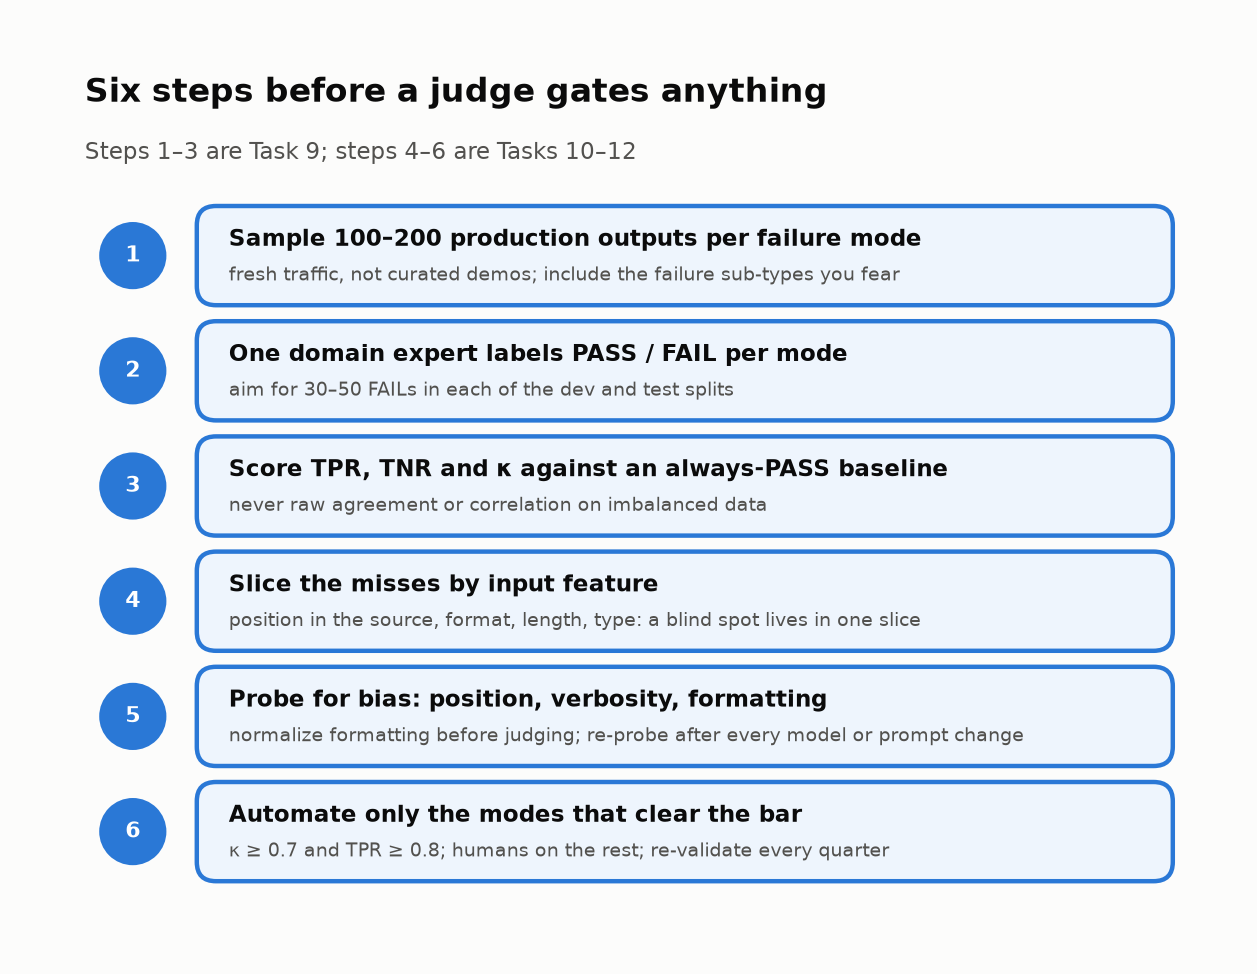

<sub>🖼️ *Tasks 9–12 on one card.*</sub>

<!-- img: judge-confusion.png -->
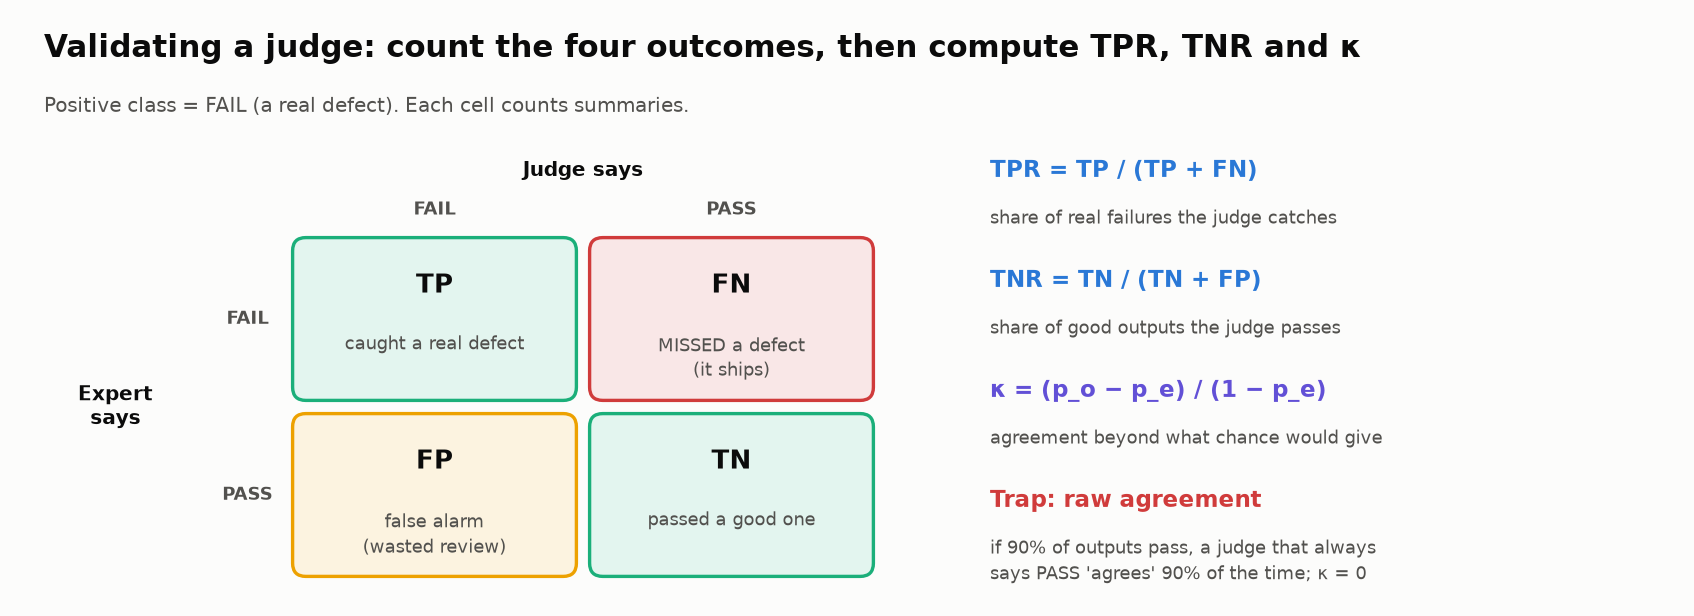

> 📘 **Concept · TPR and TNR (FAIL is the positive class)**
>
> **What it is:** TPR (true positive rate; also recall or sensitivity) = TP / (TP + FN), the share of real failures the judge catches. TNR (true negative rate; specificity) = TN / (TN + FP), the share of good outputs it passes.
>
> **What it can't tell you:** how the judge will *look* on data with a different failure rate; agreement and κ change with the mix, TPR and TNR don't.
>
> **Anchor:** a judge that always says PASS has TPR 0% and TNR 100%; on data where 90% of outputs pass, it also has 90% agreement.

> 📘 **Concept · Cohen's κ (kappa)**
>
> **What it is:** κ = (p_o − p_e) / (1 − p_e): the observed agreement p_o minus the agreement p_e the two raters' **base rates** (how often each says FAIL) would produce by luck, rescaled so 0 = chance and 1 = perfect.
>
> **What it can't tell you:** which way the judge errs. κ = 0.5 could be missed failures or false alarms; read TPR and TNR for the direction.
>
> **Anchor:** the always-PASS judge above: p_o = 0.90, p_e = 0.90, κ = 0, however impressive the 90% sounds.

`UNKNOWN` = an **abstention**: excluded from the metrics, routed to a human.

In [ ]:
# @title 🔮 Predict: on the 200, how often does an always-PASS judge agree, and what share of hidden risks does the judge catch?
always_pass_judge_agrees = "— pick one —"  # @param ["— pick one —", "A) about 50%", "B) about 75%", "C) about 90%"]
share_of_hidden_risks_caught = "— pick one —"  # @param ["— pick one —", "A) 80% or more", "B) 50 to 79%", "C) under 50%"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run** (code hidden, nothing to read): 200 synthetic summaries with injected defects and the expert's labels.

In [ ]:
# @title 🧰 Production sample: 200 synthetic summaries with injected defects and the expert's labels (hidden · 123 lines · expand if curious)
# ──────────────────────────────────────────────────────────────
# A PRODUCTION SAMPLE: 200 summaries labeled by one domain expert
# Simulates what a real team does: pull 200 summaries from last month's
# traffic and label each PASS/FAIL per failure mode. Every defect below
# is injected on purpose, so the expert labels are ground truth.
# (Synthetic data, fictional companies.)
# ──────────────────────────────────────────────────────────────
VAL_N = 200
_rng = np.random.default_rng(SEED)

_PREFIX = ["Arbor", "Beacon", "Cedar", "Delta", "Ember", "Fjord", "Granite", "Harbor", "Ion", "Juniper",
           "Keystone", "Lumen", "Meridian", "Northwind", "Orchid", "Pinnacle", "Quarry", "Redwood",
           "Summit", "Tidal", "Umber", "Vertex", "Willow", "Zephyr"]
_SUFFIX = ["Analytics", "Bancorp", "Biotech", "Capital", "Foods", "Freight", "Health", "Logistics",
           "Media", "Payments", "Retail", "Robotics", "Software", "Telecom", "Energy"]
_GOOD_EVENTS = ["Opened {n} new distribution centers", "Expanded into {n} new markets",
                "Signed {n} new enterprise contracts", "Launched {n} new products"]
_RISK_EVENTS = {"waiver": "Obtained a debt covenant waiver from lenders",
                "ceo": "Announced the CEO's departure",
                "restructuring": "Announced a restructuring with a 12% workforce reduction",
                "inquiry": "Disclosed a regulatory inquiry into its lending practices",
                "auditor": "Replaced its external auditor"}
_ACCOLADES = ["was added to the S&P MidCap 400 index", "won an industry award for customer service"]
_SPIN = [" Margins remained healthy, demonstrating resilience.",
         " The results position the company well for long-term growth.",
         " Management's strategic investments continue to pay off."]


def _pick(n, pool):
    """Choose exactly n indices from pool (deterministic, seeded)."""
    pool = np.array(sorted(pool))
    return set(_rng.choice(pool, size=n, replace=False).tolist())


ALL = set(range(VAL_N))
# Exact counts make the lab's numbers stable. Each set is one injected defect.
RISK_HEADLINE = _pick(4, ALL)                                # omits a headline negative (revenue fell QoQ)
RISK_EVENT = _pick(16, ALL - RISK_HEADLINE)                  # omits a risk EVENT (waiver, CEO exit, ...)
RISK_FAIL = RISK_HEADLINE | RISK_EVENT
RISK_EVENT_FIRST = _pick(1, RISK_EVENT)                      # the omitted event is listed FIRST in the source
HEDGED = _pick(4, ALL - RISK_FAIL)                           # discloses leverage in vague words ("watch item")
NO_EVENTS = _pick(8, ALL - RISK_FAIL - HEDGED)               # source has no events list -> judge can't tell
NUM_SUBTLE = _pick(10, ALL)                                  # growth rate off by 6-9% (relative)
NUM_GROSS = _pick(20, ALL - NUM_SUBTLE)                      # growth rate off by 15-80%
COARSE = _pick(8, ALL - NUM_SUBTLE - NUM_GROSS)              # correct but loosely rounded ("about 20%")
FAB_COUNT = _pick(10, ALL)                                   # changes a count (12 markets -> 15)
FAB_ACCOLADE = _pick(6, ALL - FAB_COUNT)                     # invents a plausible accolade
MARKDOWN = _pick(60, ALL)                                    # 30% of summaries arrive as markdown bullets
SPIN_MD = _pick(8, MARKDOWN)                                 # misleading spin, markdown-formatted
SPIN_PROSE = _pick(16, ALL - MARKDOWN)                       # misleading spin, plain prose
STRONG_OK = _pick(5, ALL - MARKDOWN - SPIN_PROSE)            # justified upbeat words in a strong quarter


def _make_item(i):
    name = f"{_PREFIX[i % 24]} {_SUFFIX[(i * 7) % 15]}"
    rev_py = float(_rng.integers(40, 400))
    yoy = float(_rng.uniform(0.02, 0.25))
    rev = round(rev_py * (1 + yoy), 1)
    qoq = -float(_rng.uniform(0.02, 0.06)) if (i in RISK_HEADLINE or i in SPIN_MD or i in SPIN_PROSE or _rng.random() < 0.15) else float(_rng.uniform(0.01, 0.06))
    rev_pq = round(rev / (1 + qoq), 1)
    ni = round(rev * float(_rng.uniform(0.05, 0.2)), 1)
    cash = float(_rng.integers(30, 300))
    debt = round(cash * (2.6 if i in HEDGED else float(_rng.uniform(0.3, 1.8))), 0)
    good_t = _GOOD_EVENTS[i % 4]
    n_good = int(_rng.integers(3, 13))
    events = [good_t.format(n=n_good)]
    has_risk_event = i in RISK_EVENT or _rng.random() < 0.2
    risk_event = list(_RISK_EVENTS.values())[i % 5] if has_risk_event else None
    if risk_event:
        events = [risk_event] + events if i in RISK_EVENT_FIRST else events + [risk_event]
    source = {"company": name, "revenue_m": rev, "revenue_prev_quarter_m": rev_pq, "revenue_prev_year_m": rev_py,
              "net_income_m": ni, "total_debt_m": debt, "cash_m": cash,
              "notable_events": None if i in NO_EVENTS else events}

    true_yoy = round((rev - rev_py) / rev_py * 100, 1)
    stated_yoy = true_yoy
    if i in NUM_SUBTLE:
        stated_yoy = round(true_yoy * (1 + float(_rng.uniform(0.06, 0.09))), 1)
    elif i in NUM_GROSS:
        stated_yoy = round(true_yoy * (1 + float(_rng.uniform(0.15, 0.8))), 1)
    yoy_txt = f"about {round(true_yoy)}%" if i in COARSE else f"{stated_yoy}%"
    stated_n = n_good + 3 if i in FAB_COUNT else n_good
    n_txt = str(stated_n)

    facts = [("Revenue", f"${rev}M, up {yoy_txt} year-over-year")]
    if qoq < 0 and i not in RISK_HEADLINE:
        facts.append(("Sequential", f"down {abs(qoq) * 100:.1f}% from last quarter"))
    facts.append(("Net income", f"${ni}M"))
    if debt > 2 * cash:
        facts.append(("Balance sheet", "leverage remains a watch item" if i in HEDGED
                      else f"${debt:.0f}M of debt against ${cash:.0f}M of cash"))
    else:
        facts.append(("Balance sheet", f"${cash:.0f}M of cash"))
    facts.append(("Highlight", good_t.format(n=n_txt).lower()))
    if risk_event and i not in RISK_EVENT:
        facts.append(("Risk", risk_event[0].lower() + risk_event[1:]))
    if i in FAB_ACCOLADE:
        facts.append(("Recognition", f"{_ACCOLADES[i % 2]}"))
    spin = (i in SPIN_MD or i in SPIN_PROSE)

    if i in MARKDOWN:
        lines = [f"### {name}: Q3 2026 highlights"] + [f"- **{k}:** {v}" for k, v in facts]
        if spin:
            lines.append(f"- **Outlook:** {_SPIN[i % 3].strip()}")
        text = "\n".join(lines)
    else:
        text = " ".join(f"{k}: {v}." for k, v in facts)
        text = f"{name} Q3 2026. " + text + (_SPIN[i % 3] if spin else (" A strong quarter." if i in STRONG_OK else ""))

    human = {  # the expert's labels, one binary verdict per failure mode
        "numbers_correct": "FAIL" if (i in NUM_SUBTLE or i in NUM_GROSS) else "PASS",
        "grounded": "FAIL" if (i in FAB_COUNT or i in FAB_ACCOLADE) else "PASS",
        "risks_disclosed": "FAIL" if i in RISK_FAIL else "PASS",
        "balanced_framing": "FAIL" if spin else "PASS",
    }
    meta = {"markdown": i in MARKDOWN, "omission": "headline" if i in RISK_HEADLINE else "event" if i in RISK_EVENT else None,
            "true_yoy": true_yoy, "stated_yoy": stated_yoy}
    return {"id": f"P{i:03d}", "i": i, "source": source, "summary": text, "human": human, "meta": meta}


production_sample = [_make_item(i) for i in range(VAL_N)]
val_df = pd.DataFrame([{"id": it["id"], **{f"human_{m}": v for m, v in it["human"].items()}} for it in production_sample])


▶️ **Run:** how rare each failure is → note the FAIL share for `risks_disclosed`.

In [ ]:
# A first look at the production sample: how rare each failure is, and what the summaries look like.
print(f"Loaded {VAL_N} expert-labeled production summaries.\n")
print("Share of summaries the expert labeled FAIL, per failure mode:")
for m in MODES:
    k = (val_df[f"human_{m}"] == "FAIL").sum()
    print(f"  {m:18s} {k:3d} FAIL / {VAL_N}  ({k / VAL_N:.0%})")
print("\nTwo examples. ~30% of summaries arrive as markdown bullets, the rest as prose:\n")
print(next(it for it in production_sample if not it["meta"]["markdown"])["summary"], "\n")
print(next(it for it in production_sample if it["meta"]["markdown"])["summary"])


▶️ **Run** (code hidden; its blind spots are the Task 10 puzzle, so don't open it yet): the simulated judge.

In [ ]:
# @title 🤖 Simulated LLM judge for the production sample (run me; read it AFTER Task 10)
# A stand-in for a real LLM judge, so the lab runs offline and gives everyone the same numbers.
# It reads the SOURCE and the SUMMARY text and applies the binary rubric, with a few blind spots
# planted on purpose: the kind you only discover by validating against human labels (Task 9).
def _coin(item_id, mode, rate):
    """Deterministic 'randomness': LLM judges are noisy, and this mimics occasional misses."""
    h = int(hashlib.md5(f"{item_id}|{mode}".encode()).hexdigest(), 16) % 1000
    return h < rate * 1000


def simulated_judge(item, mode):
    src, text, low = item["source"], item["summary"], item["summary"].lower()
    if mode == "numbers_correct":
        true_yoy = (src["revenue_m"] - src["revenue_prev_year_m"]) / src["revenue_prev_year_m"] * 100
        m = re.search(r"up (about )?([\d.]+)%", text)
        stated = float(m.group(2))
        if m.group(1):                                   # "about 20%": judge is strict about loose rounding
            bad = abs(stated - true_yoy) >= 0.3
        else:                                            # eyeballs the growth rate: misses small relative errors
            bad = abs(stated - true_yoy) / abs(true_yoy) > 0.075
        return ("FAIL", f"Stated YoY {stated}% vs recomputed {true_yoy:.1f}%.") if bad else ("PASS", "Growth rate checks out.")
    if mode == "grounded":
        if src["notable_events"] is None:
            return "UNKNOWN", "Source has no events list; can't verify the highlight."
        n_stated = int(re.search(r"highlight:\**\s*\D*(\d+)", low).group(1))
        n_source = [int(x) for e in src["notable_events"] for x in re.findall(r"\d+", e)]
        if n_stated not in n_source:
            return "FAIL", f"Summary says {n_stated}; source says {n_source}."
        if "industry award" in low:                     # award isn't in the source -> caught
            return "FAIL", "Award not mentioned in the source."
        # Blind spot: "added to the S&P MidCap 400" sounds like world knowledge, so the judge doesn't check it
        return "PASS", "Specific details match the source."
    if mode == "risks_disclosed":
        if src["notable_events"] is None:
            return "UNKNOWN", "Source events list missing; can't tell whether a risk event was omitted."
        if src["revenue_m"] < src["revenue_prev_quarter_m"] and "down" not in low:
            return "FAIL", "Revenue fell quarter-over-quarter; the summary doesn't say so."
        if src["total_debt_m"] > 2 * src["cash_m"] and f"${src['total_debt_m']:.0f}m" not in low:
            return "FAIL", "Debt exceeds 2x cash and the debt figure is missing."
        first = src["notable_events"][0]               # Blind spot: only reads the FIRST event closely
        for key, event in _RISK_EVENTS.items():
            if first == event and key not in low:
                return "FAIL", f"Omits: '{first}'."
        return "PASS", "Material negatives are disclosed."
    if mode == "balanced_framing":
        spin = any(p in low for p in ["healthy", "resilience", "position the company", "strategic investments"])
        declined = src["revenue_m"] < src["revenue_prev_quarter_m"]
        if item["meta"]["markdown"]:                   # Blind spot: tidy bullets + bold read as "professional"
            spin = spin and _coin(item["id"], mode, 0.15)
        elif spin and _coin(item["id"], mode, 0.06):
            spin = False
        if (spin and declined) or "a strong quarter" in low:
            return "FAIL", "Upbeat framing that the numbers don't support."
        return "PASS", "Tone matches the data."
    raise ValueError(mode)


print("🤖 simulated_judge(item, mode) ready. Its blind spots stay hidden until Task 10.")

✋ **Your turn:** score the risk judge by hand before the scorecard does.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_rj = [(it["human"]["risks_disclosed"], simulated_judge(it, "risks_disclosed")[0]) for it in production_sample]
_rj = [(h, j) for h, j in _rj if j != "UNKNOWN"]
_risk_counts = tuple(sum((h, j) == pair for h, j in _rj) for pair in
                     [("FAIL", "FAIL"), ("FAIL", "PASS"), ("PASS", "FAIL"), ("PASS", "PASS")])
_ref_stamp = (_risk_counts[2] + _risk_counts[3]) / len(_rj)
_ref_tpr = _risk_counts[0] / (_risk_counts[0] + _risk_counts[1])

In [ ]:
# ✋ Your turn: the risk judge's 2×2 on the summaries it decided (FAIL = positive class).
tp, fn, fp, tn = _risk_counts
print(f"TP {tp} · FN {fn} · FP {fp} · TN {tn}   →  raw agreement {(tp + tn) / (tp + fn + fp + tn):.1%}")

my_stamp = ...   # ✏️ agreement of a "judge" that ALWAYS says PASS (it never reads the summary)
my_tpr = ...     # ✏️ share of the real failures (expert FAIL) this judge caught

check("Always-PASS agreement", my_stamp, _ref_stamp,
      hint="Always-PASS is right exactly when the expert said PASS. Which two cells are those?",
      success=f"{_ref_stamp:.1%}: a rubber stamp lands within half a point of the VP's 90%.")
check("TPR of the risk judge", my_tpr, _ref_tpr,
      hint="Of the summaries that really hide a risk (TP + FN), what share did the judge flag?",
      success=f"{_ref_tpr:.0%}: it misses {fn} of {tp + fn} hidden risks while 'agreeing' 90%.")

▶️ **Run:** the scorecard function → note the 👀 line: the always-PASS baseline is computed for every mode.

In [ ]:
# ──────────────────────────────────────────────────────────────
# META-EVALUATION: score the judge against the expert, per failure mode.
# ──────────────────────────────────────────────────────────────
def judge_scorecard(human, judge):
    """Positive class = FAIL (a real defect). UNKNOWN verdicts are abstentions: excluded, but counted."""
    pairs = [(h, j) for h, j in zip(human, judge) if j != "UNKNOWN"]
    h = np.array([p[0] for p in pairs]); j = np.array([p[1] for p in pairs])
    tp, fn = int(((h == "FAIL") & (j == "FAIL")).sum()), int(((h == "FAIL") & (j == "PASS")).sum())
    fp, tn = int(((h == "PASS") & (j == "FAIL")).sum()), int(((h == "PASS") & (j == "PASS")).sum())
    return {
        "n": len(pairs), "abstained": len(human) - len(pairs), "tp": tp, "fn": fn, "fp": fp, "tn": tn,
        "raw_agreement": (tp + tn) / len(pairs),
        "always_pass_agreement": (fp + tn) / len(pairs),   # 👀 Look at: a "judge" that never reads the summary
        "tpr": tp / (tp + fn) if tp + fn else float("nan"),  # real failures caught
        "tnr": tn / (tn + fp) if tn + fp else float("nan"),  # good summaries passed
        "kappa": cohen_kappa_score(h, j),                    # agreement beyond chance
    }


def wilson(k, n, z=1.96):
    """95% confidence interval for a proportion k/n (Lab 05b explains when and why)."""
    p, d = k / n, 1 + z * z / n
    c, r = p + z * z / (2 * n), z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (c - r) / d, (c + r) / d


▶️ **Run:** scores all four judges on the 200 → compare *raw_agreement* with *always_pass_agreement*.

In [ ]:
# Score the judge against the expert on all 200, per failure mode.
VALIDATE_REAL_JUDGE = False   # True (with a real PROVIDER) re-runs this on a real model: 800 calls, see Stretch C


def production_verdict(item, mode):
    if PROVIDER != "mock" and VALIDATE_REAL_JUDGE:
        return call_real_judge(item["source"], item["summary"], mode).verdict
    return simulated_judge(item, mode)[0]


for m in MODES:
    val_df[f"judge_{m}"] = [production_verdict(it, m) for it in production_sample]
card = pd.DataFrame({m: judge_scorecard(val_df[f"human_{m}"], val_df[f"judge_{m}"]) for m in MODES}).T
pct = lambda x: f"{x:.1%}"
print(card[["n", "abstained", "tp", "fn", "fp", "tn"]].astype(int).to_string())
print()
print(card[["raw_agreement", "always_pass_agreement", "tpr", "tnr", "kappa"]].astype(float).to_string(
    formatters={"raw_agreement": pct, "always_pass_agreement": pct, "tpr": pct, "tnr": pct,
                "kappa": lambda x: f"{x:.2f}"}))


▶️ **Run** (code hidden): the chart, confusion tiles and the plot-twist card.

In [ ]:
# @title 🧰 Reveal: chart, confusion tiles and the plot-twist cards (hidden · 56 lines · expand if curious)
# ── Chart: raw agreement looks great everywhere; TPR and κ tell the real story ──
fig, ax = plt.subplots(figsize=(9.5, 4.0))
x, w = np.arange(len(MODES)), 0.26
for k, (col, label, color) in enumerate([("raw_agreement", "Raw agreement", PALETTE[0]),
                                         ("tpr", "TPR (failures caught)", PALETTE[1]),
                                         ("kappa", "Cohen's κ", PALETTE[6])]):
    vals = card[col].astype(float).values
    bars = ax.bar(x + (k - 1) * w, vals, w, color=color, label=label)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.2f}", ha="center", fontsize=8.5, color="#0b0b0b")
for i, m in enumerate(MODES):   # dotted tick: what a judge that always says PASS would score on raw agreement
    ax.plot([i - 1.5 * w, i - 0.5 * w], [card.loc[m, "always_pass_agreement"]] * 2, color="#0b0b0b", lw=1.6, ls=":")
ax.text(len(MODES) - 0.5, 1.07, "dotted line = always-PASS baseline", ha="right", fontsize=9, color="#52514e")
ax.set_xticks(x); ax.set_xticklabels(MODES); ax.set_ylim(0, 1.13); ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.1))
rk = card.loc["risks_disclosed"]
ax.set_title(f"{rk.raw_agreement:.0%} agreement, κ = {rk.kappa:.2f}: the risk judge misses "
             f"{int(rk.fn)} of {int(rk.tp + rk.fn)} hidden risks")
plt.tight_layout(); plt.show()

tiles([
    ("Caught (TP)", int(rk.tp), "hidden risks flagged", "good"),
    ("Missed (FN)", int(rk.fn), "hidden risks that would ship", "critical"),
    ("False alarms (FP)", int(rk.fp), "good summaries flagged", "warning"),
    ("Correct passes (TN)", int(rk.tn), f"+ {int(rk.abstained)} UNKNOWN → human", None),
])

pos = int(rk.tp + rk.fn)
lo, hi = wilson(int(rk.tp), pos)
r6 = np.corrcoef([it["human_quality_score"] for it in financial_dataset],
                 [LIKERT_V1[it["id"]] for it in financial_dataset])[0, 1]
best = card["kappa"].astype(float).idxmax()
insight(
    f"The risk judge agrees with the expert {rk.raw_agreement:.1%} of the time. "
    f"A judge that always says PASS scores {rk.always_pass_agreement:.1%}",
    f"Only {pos} of {int(rk.n)} decided summaries hide a material risk, so agreement is dominated by easy PASSes. "
    f"κ removes that luck: **{rk.kappa:.2f}** (vs {card.loc[best, 'kappa']:.2f} for `{best}`). TPR shows the damage: "
    f"it catches **{int(rk.tp)} of {pos}** hidden risks ({rk.tpr:.0%}; 95% CI {lo:.0%}–{hi:.0%}: the range of true "
    f"rates consistent with so few FAIL labels, n = {pos}), so "
    f"**{int(rk.fn)} summaries hiding a covenant waiver, a CEO exit or layoffs would reach a portfolio manager.** "
    f"Last quarter's 1–5 judge looked even better on paper: r = {r6:.2f} with the expert on 6 curated summaries.\n"
    "**Rule of thumb: on imbalanced data, report TPR, TNR and κ per failure mode; never raw agreement or "
    "correlation.** This course's bar for letting a judge gate a release-blocking mode alone: κ ≥ 0.7 and TPR ≥ 0.8.",
    kind="surprise",
)
insight(
    "How many labels you need, and what 'good enough' means",
    "The Husain/Shankar evals FAQ (Sept 2026): label 100–200 examples per failure mode, with roughly 30–50 FAILs in "
    f"*each* of the dev split (labels you tune the prompt on) and the test split "
    f"(held-out labels you score it on once). This sample has {pos} risk FAILs in total, which is why the CI above is so "
    "wide. HealthBench (OpenAI, 2025) found model–physician grading agreement about equal to physician–physician "
    "agreement (both roughly 55–75% in a later meta-analysis): **a judge's ceiling is human–human agreement, not "
    "100%**, so have a second expert label a slice too.",
    kind="research",
)

# ── grades the 🔮 predictions above ──
_p_stamp = "A" if rk.always_pass_agreement < 0.62 else "B" if rk.always_pass_agreement < 0.83 else "C"
_p_tpr = "A" if rk.tpr >= 0.8 else "B" if rk.tpr >= 0.5 else "C"

▶️ **Run:** grades your two predictions.

In [ ]:
quiz("Your prediction: always-PASS agreement", always_pass_judge_agrees, correct=_p_stamp,
     why=f"{rk.always_pass_agreement:.1%}: on data that is ~90% PASS, saying PASS is ~90% 'right'.")
quiz("Your prediction: hidden risks caught", share_of_hidden_risks_caught, correct=_p_tpr,
     why=f"{rk.tpr:.0%} ({int(rk.tp)} of {int(rk.tp + rk.fn)}). The 168 easy PASSes carried the agreement.")

🔍 **What just happened:** <mark>the VP's 90% is true and nearly meaningless.</mark> Luck alone agrees 85.9% when both raters say PASS almost always; κ = 0.30 is the share of the rest the judge earned.

<!-- img: comic-rubber-stamp.png -->
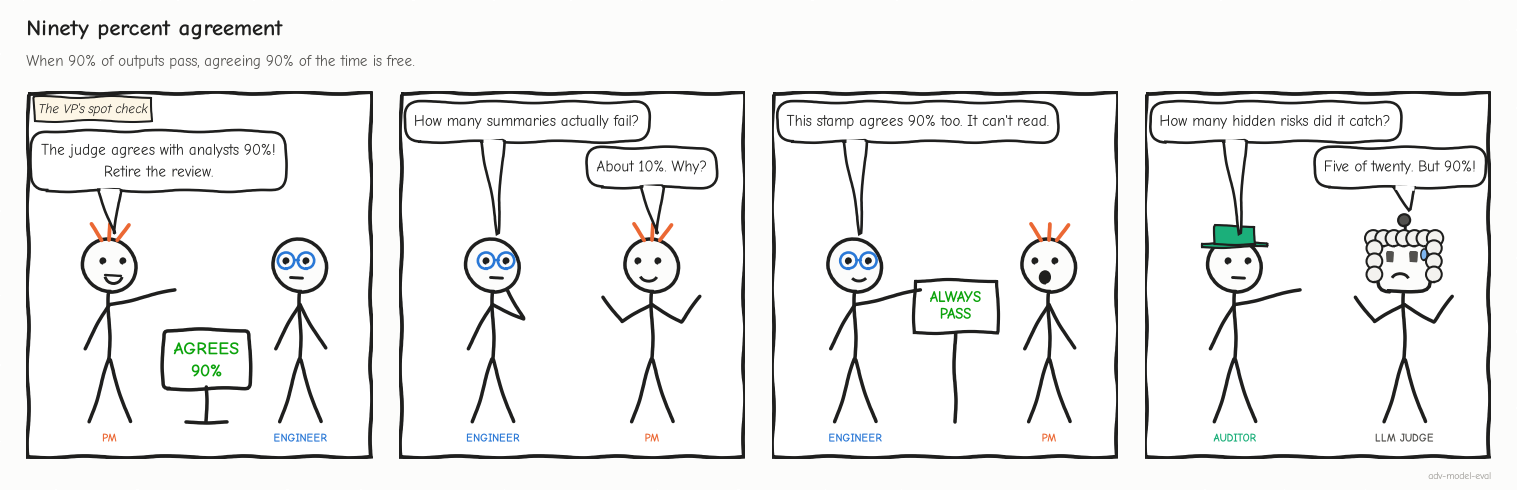

<!-- img: kappa-chance.png -->
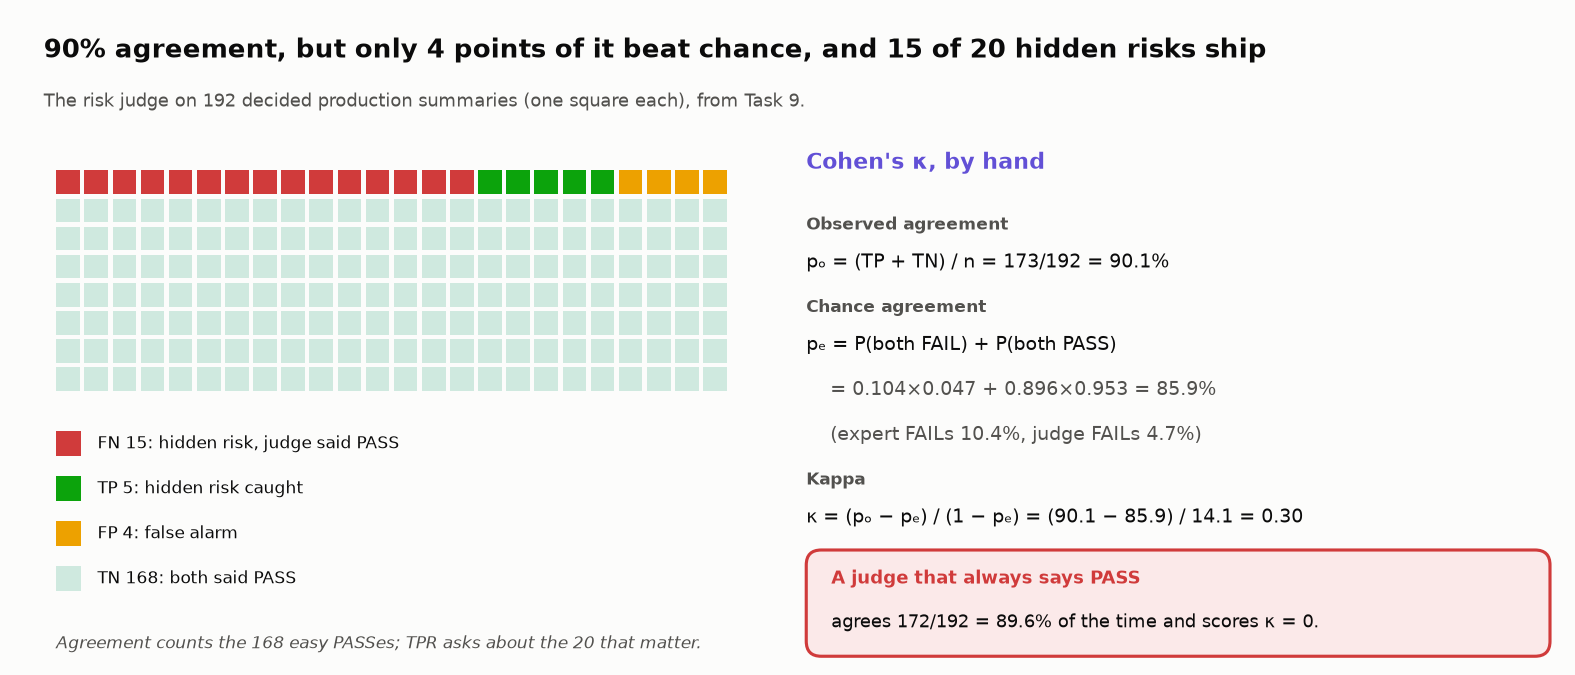

<sub>🖼️ *With only 20 FAIL labels, the TPR's 95% CI is 11–47%.*</sub>

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** `risks_disclosed  192  8  5  15  4  168` and `90.1%  89.6%  25.0%  97.7%  0.30`; the other three modes show TPR 71–87%. Chart: **"90% agreement, κ = 0.30: the risk judge misses 15 of 20 hidden risks"**.
</details>

🗣️ **Say it to a colleague:** "90% agreement is what a rubber stamp gets when 90% of outputs are fine. Ask what share of the failures it caught."

**🎛️ The VP's dashboard:** what if fewer summaries hid a risk, with the same judge? ▶️ **Run** the next two cells: the arithmetic, then the drawing (hidden).

In [ ]:
# 🎛️ THE VP'S DASHBOARD: same judge, different data. The arithmetic behind every slider position:

JUDGE_TNR = float(card.loc["risks_disclosed", "tnr"])          # the risk judge's measured TNR (97.7%)
JUDGE_TPR = float(card.loc["risks_disclosed", "tpr"])          # ... and TPR (25%)
SAMPLE_RATE = (card.loc["risks_disclosed", "tp"] + card.loc["risks_disclosed", "fn"]) / card.loc["risks_disclosed", "n"]


def expected_scores(rate, tpr, tnr=JUDGE_TNR):
    """What a judge with this TPR/TNR scores when `rate` of summaries truly FAIL (expected values, no noise)."""
    tp, fn, fp, tn = rate * tpr, rate * (1 - tpr), (1 - rate) * (1 - tnr), (1 - rate) * tnr
    p_o = tp + tn                                     # raw agreement
    q = tp + fp                                       # how often the judge says FAIL
    p_e = rate * q + (1 - rate) * (1 - q)             # 👀 Look at: chance agreement moves with the failure rate
    return {"agreement": p_o, "always_pass": 1 - rate, "kappa": (p_o - p_e) / (1 - p_e), "tpr": tpr,
            "shipped_per_1000": 1000 * fn, "fails_per_1000": 1000 * rate}


In [ ]:
# @title 🧰 Dashboard drawing: draw_dashboard(per_1000, tpr) + the crossover (hidden · 65 lines)
import io
from IPython.display import Image as _Img, display  # noqa: F401


def draw_dashboard(per_1000=round(1000 * SAMPLE_RATE), tpr=JUDGE_TPR):
    rate = per_1000 / 1000
    s = expected_scores(rate, tpr)
    xs = np.geomspace(0.005, 0.5, 120)
    curves = [expected_scores(x, tpr) for x in xs]
    fig = plt.figure(figsize=(10, 5.2))
    # ── tile row, drawn inside the figure so one image updates as a unit ──
    tiles_ = [("Raw agreement", f"{s['agreement']:.1%}", STATUS["good"] if s["agreement"] >= 0.9 else STATUS["warning"],
               "the VP's number"),
              ("Always-PASS stamp", f"{s['always_pass']:.1%}", "#b9b8b3", "reads nothing"),
              ("Cohen's κ", f"{s['kappa']:.2f}", STATUS["good"] if s["kappa"] >= 0.7 else STATUS["critical"], "bar: 0.70"),
              ("Hidden risks shipped", f"{s['shipped_per_1000']:.0f} / 1,000", STATUS["critical"] if s["shipped_per_1000"] >= 1 else STATUS["good"],
               f"of {s['fails_per_1000']:.0f} that hide a risk")]
    for k, (lab, val, col, note) in enumerate(tiles_):
        ax_t = fig.add_axes([0.02 + k * 0.245, 0.765, 0.225, 0.15]); ax_t.axis("off")
        ax_t.add_patch(plt.Rectangle((0, 0), 1, 1, fc="#fcfcfb", ec="#e4e3df", transform=ax_t.transAxes))
        ax_t.add_patch(plt.Rectangle((0, 0.9), 1, 0.1, fc=col, ec="none", transform=ax_t.transAxes))
        ax_t.text(0.06, 0.72, lab, fontsize=9, color="#52514e", transform=ax_t.transAxes)
        ax_t.text(0.06, 0.32, val, fontsize=17, weight="bold", color="#0b0b0b", transform=ax_t.transAxes)
        ax_t.text(0.06, 0.08, note, fontsize=8, color="#52514e", transform=ax_t.transAxes)
    ax = fig.add_axes([0.07, 0.11, 0.71, 0.58])
    agree = np.array([c["agreement"] for c in curves]); stamp = np.array([c["always_pass"] for c in curves])
    ax.fill_between(xs, 0, 1.08, where=stamp > agree, color=STATUS["critical"], alpha=0.07, lw=0)
    if (stamp > agree).any():
        ax.text(xs[stamp > agree][0] * 1.1, 0.04, "shaded: the stamp out-agrees the judge", fontsize=8.5,
                color=STATUS["critical"], zorder=5, bbox=dict(fc="#fcfcfb", ec="none", alpha=0.9, pad=1.5))
    ends = []
    for key, lab, col, ls in [("agreement", "raw agreement", PALETTE[0], "-"), ("always_pass", "always-PASS stamp", "#0b0b0b", ":"),
                              ("kappa", "Cohen's κ", PALETTE[6], "-"), ("tpr", "TPR (risks caught)", PALETTE[1], "--")]:
        ys = [c[key] for c in curves]
        ax.plot(xs, ys, color=col, ls=ls, lw=2)
        ends.append([ys[-1], lab, col])
    ends.sort(key=lambda e: e[0])
    for k in range(1, len(ends)):                      # nudge end labels apart so they never collide
        ends[k][0] = max(ends[k][0], ends[k - 1][0] + 0.075)
    for y, lab, col in ends:
        ax.text(0.53, y, lab, color=col, fontsize=9, va="center", clip_on=False)
    ax.axvline(rate, color="#0b0b0b", lw=1.2)
    ax.plot([rate] * 2, [s["agreement"], s["always_pass"]], "o", color="#0b0b0b", ms=4)
    ax.axvline(SAMPLE_RATE, color="#b9b8b3", lw=1, ls="--")
    ax.text(SAMPLE_RATE * 1.04, 1.035, "Task 9 sample", fontsize=8, color="#52514e")
    ax.set_xscale("log"); ax.set_xlim(0.005, 0.5); ax.set_ylim(0, 1.08)
    ax.set_xticks([0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5]); ax.set_xticklabels(["0.5%", "1%", "2%", "5%", "10%", "20%", "50%"])
    ax.set_xlabel("share of summaries that truly hide a risk (log scale)")
    if s["always_pass"] > s["agreement"]:
        title = (f"At {s['fails_per_1000']:.0f} risky per 1,000, a stamp that reads nothing out-agrees the judge "
                 f"({s['always_pass']:.0%} vs {s['agreement']:.0%})")
    else:
        title = (f"{s['fails_per_1000']:.0f} risky per 1,000: agreement {s['agreement']:.0%}, "
                 f"yet {s['shipped_per_1000']:.0f} of them ship")
    fig.suptitle(title, x=0.02, y=0.985, ha="left", fontsize=12.5, weight="bold")
    buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=100); plt.close(fig)
    return _Img(buf.getvalue())


crossover = (1 - JUDGE_TNR) / (JUDGE_TPR + 1 - JUDGE_TNR)   # where TP gains = FP losses: FPR / (TPR + FPR)
print(f"Below {crossover:.1%} risky, the always-PASS stamp out-agrees this judge.")
for r in (0.01, SAMPLE_RATE, 0.4):
    e = expected_scores(r, JUDGE_TPR)
    print(f"{r:5.1%} risky → agreement {e['agreement']:.1%} · always-PASS {e['always_pass']:.1%} · κ {e['kappa']:.2f} · TPR {e['tpr']:.0%}")


🎛️ **Experiment:** drag `RISKY_PER_1000` down to **20** and run: who agrees more, the judge or the stamp? Then drag `JUDGE_TPR_TRY` to **0.85**.

In [ ]:
# 🎛️ Same judge (TNR 97.7%), different data. Defaults reproduce Task 9's sample.
RISKY_PER_1000 = 104  # @param {type:"slider", min:5, max:500, step:1}
JUDGE_TPR_TRY = 0.25  # @param {type:"slider", min:0.05, max:1.0, step:0.05}

display(draw_dashboard(RISKY_PER_1000, JUDGE_TPR_TRY))

🔍 **What just happened:** at 20 per 1,000 the stamp out-agrees the judge (98% vs 96%) and κ falls to 0.13, for the **same** judge.

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Default title **"104 risky per 1,000: agreement 90%, yet 78 of them ship"**; printed crossover **8.5%**.
</details>

In [ ]:
# @title ❓ Quick check: which numbers describe the judge alone, whatever the failure rate?
answer = "— pick one —"  # @param ["— pick one —", "A) Raw agreement and κ", "B) All four", "C) Only κ, because it corrects for chance", "D) TPR and TNR"]
quiz('What belongs to the judge?', answer, correct="D",
     why="TPR and TNR are computed within the FAIL and PASS groups, so the mix does not move them. Agreement and κ describe the judge on this data. Compare judges across quarters by TPR and TNR.",
     wrong={"A": 'The dashboard moved both with the data while the judge stayed fixed.',
          "B": 'Agreement and κ shifted when only the failure rate changed.',
          "C": 'κ fell from 0.30 to 0.13 with the same judge: chance agreement itself depends on the mix.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>On imbalanced data, agreement is the easy cases agreeing: ask for TPR on the failures.</b></font>

</td></tr></table>

---

## Task 10: Read the Judge's Misses — Error Analysis on the Evaluator 🔎

<big><b>Useless as a number, fixable as a pattern.</b></big>

> 🎯 **Goal:** **slice** the judge's misses by an input feature and name the pattern.<br>
> ❓ **The question:** are the misses random?<br>
> 👀 **Watch for:** where in the source the missed risk sits.

<!-- img: risk-judge-confusion.png -->
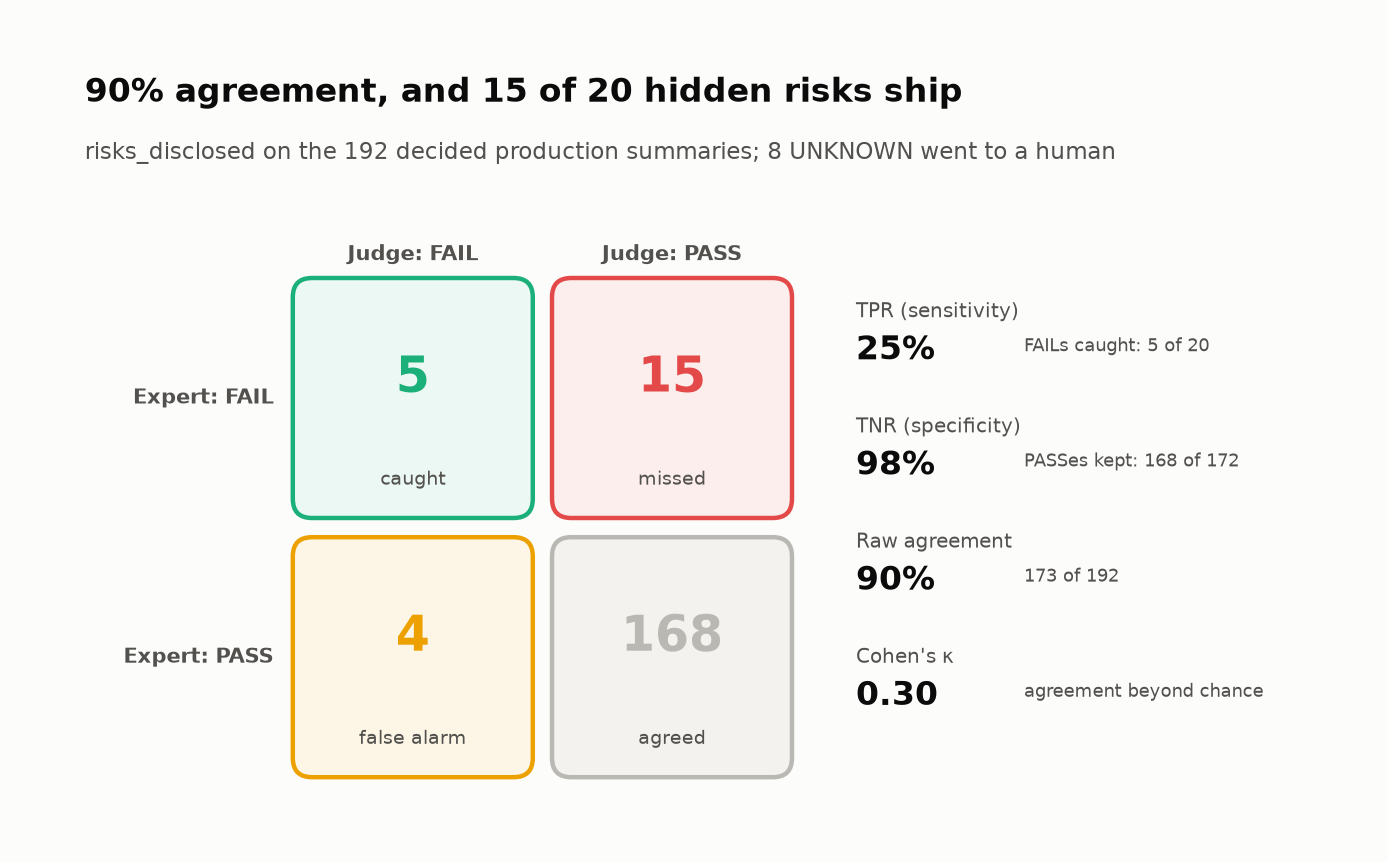

▶️ **Run:** misses by omission type and by format, then three example misses with their sources.

In [ ]:
# ──────────────────────────────────────────────────────────────
# ERROR ANALYSIS OF THE JUDGE: slice disagreements by input features
# ──────────────────────────────────────────────────────────────
v = val_df.assign(omission=[it["meta"]["omission"] for it in production_sample],
                  fmt=["markdown" if it["meta"]["markdown"] else "prose" for it in production_sample])


def catch_table(rows, by, mode):
    g = rows.groupby(by)                      # 👀 Look at: one input feature per slice
    return pd.DataFrame({"expert FAIL": g.size(),
                         "judge caught": g[f"judge_{mode}"].apply(lambda s: int((s == "FAIL").sum()))})


risk_tab = catch_table(v[v["human_risks_disclosed"] == "FAIL"], "omission", "risks_disclosed")
frame_tab = catch_table(v[v["human_balanced_framing"] == "FAIL"], "fmt", "balanced_framing")
print("risks_disclosed: hidden risks by kind of omission\n", risk_tab.to_string(), "\n")
print("balanced_framing: spin by format\n", frame_tab.to_string(), "\n")

print("Three missed hidden risks (expert FAIL, judge PASS):")
missed = [it for it in production_sample
          if it["human"]["risks_disclosed"] == "FAIL" and simulated_judge(it, "risks_disclosed")[0] == "PASS"]
for it in missed[:3]:
    print(f"\n  {it['id']} · source events: {it['source']['notable_events']}")
    print(f"     summary: {it['summary'][:150]}...")
    print(f"     judge critique: {simulated_judge(it, 'risks_disclosed')[1]}")


✋ **Your turn:** read the three misses and find the blind spot.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_pos = {("first" if evs.index(e) == 0 else "last") for it in missed for evs in [it["source"]["notable_events"]]
        for e in evs if e in _RISK_EVENTS.values()}
_ref_position = _pos.pop() if len(_pos) == 1 else "mixed"

In [ ]:
# ✋ Your turn: in each miss above, where in `source events` does the omitted risk sit?
my_position = ...   # ✏️ "first" or "last"

check("Where the judge stops reading", my_position, _ref_position,
      hint="Compare each miss's source events with what its summary mentions. Which event is missing, and where is it in the list?",
      success=f"Last, in all {len(missed)} misses: the judge reads the first event closely and skims the rest. You can't read a real judge's code; slicing its misses is how you find this.")

▶️ **Run** (code hidden): the card that names both blind spots.

In [ ]:
# @title 🧰 Card: the misses aren't random (hidden · 15 lines · expand if curious)
h_n, h_c = risk_tab.loc["headline"]
e_n, e_c = risk_tab.loc["event"]
md_n, md_c = frame_tab.loc["markdown"]
pr_n, pr_c = frame_tab.loc["prose"]
insight(
    f"The misses aren't random: the risk judge caught {h_c} of {h_n} headline omissions but only {e_c} of {e_n} "
    f"omitted risk events",
    "In every miss above, the omitted event sits at the **end** of the source's events list, and the judge reads "
    "only the first event closely. The framing judge has a different blind spot: it caught "
    f"**{pr_c} of {pr_n}** spin summaries written as prose but only **{md_c} of {md_n}** formatted as markdown "
    "bullets.\n**Rule of thumb: when a judge disagrees with humans, slice the misses by input features (position, "
    "format, length, type) before you touch the prompt. The fix is usually specific: e.g. 'first list every event "
    "in the source, then check each one'.**",
)


🔍 **What just happened:** "κ = 0.30" became two fixable blind spots: the risk judge skims late events, the framing judge goes easy on markdown. Open the 🤖 cell in Task 9 to confirm.

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Events caught **1 of 16**, headlines **4 of 4**; markdown spin **2 of 8**, prose **15 of 16**.
</details>

🗣️ **Say it to a colleague:** "κ tells you the judge is unreliable; slicing the misses tells you where."

In [ ]:
# @title ❓ Quick check: the numbers judge clears the bar (κ 0.86, TPR 87%). Should it gate numbers alone?
answer = "— pick one —"  # @param ["— pick one —", "A) No: recomputation in code is the gate; the judge is a second opinion", "B) Yes: it clears the bar, so retire the Task 6 recomputation", "C) No: any judge under 95% TPR is unusable"]
quiz('Gate numbers with the judge?', answer, correct="A",
     why="For anything code can recompute, the deterministic check is exact and free. Use the judge for numbers code cannot derive.",
     wrong={"B": 'Recomputation catches every misstated growth rate; the judge misses 4 of 30.',
          "C": 'The bar is a policy you set per mode. The problem is using a judge for arithmetic at all.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Slice a judge's misses by input feature before you touch its prompt.</b></font>

</td></tr></table>

---

## Task 11: Probe the Judge for Bias — Position, Verbosity, Formatting 🧲

<big><b>A judge swayed by bullet points can be gamed.</b></big>

> 🎯 **Goal:** three **bias probes**: change something that should not matter, re-judge, measure the shift.<br>
> ❓ **The question:** which moves a judge most: order, length or formatting?<br>
> 👀 **Watch for:** which shifts are bigger than noise.

Pairwise: the judge picks the better of two summaries with **identical facts**; fair = 50%. Judges L, C, N are simulated, with bias directions from 2026 studies.

> 📘 **Concept · Bias probe**
>
> **What it is:** change something that should not matter (answer order, length, formatting) between two outputs with identical facts, re-judge, and measure the shift from the fair 50%.
>
> **What it can't tell you:** whether the judge is *accurate*. An unbiased judge can still miss failures; that was Task 9's job.
>
> **Anchor:** if bold bullets win 80% of pairs against the same words in prose, the judge is grading style. Strip the formatting and the probe should come back near 50%.

Probes: **position** (swap order) · **verbosity** (add fluff) · **formatting** (bold bullets) · **mitigation** (strip markdown first).

In [ ]:
# @title 🔮 Predict: same words, rewritten as bold bullets. How far does a judge's preference move?
markdown_moves_a_judge_by = "— pick one —"  # @param ["— pick one —", "A) under 5 pp", "B) 10 to 20 pp", "C) 30 pp or more"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run** (code hidden): the three simulated judges and the markdown helpers.

In [ ]:
# @title 🧰 Three simulated pairwise judges (L, C, N) + the markdown / strip_markdown helpers (hidden · 41 lines · expand if curious)
# ──────────────────────────────────────────────────────────────
# BIAS PROBES: change something that should NOT matter, re-judge, measure the shift.
# Pairwise setup: the judge sees two summaries with IDENTICAL facts and picks the better one.
# A fair judge picks each side 50% of the time, so any shift away from 50% is bias.
# Three simulated judges whose bias directions mirror the 2026 literature (see the research card).
# ──────────────────────────────────────────────────────────────
FLUFF = (" Investors should weigh these results in the context of broader market conditions."
         " As always, past performance is not a guarantee of future results.")


def to_markdown(prose):
    """Same facts, dressed up: '### header' + bold bullet points."""
    head, *facts = [s for s in prose.split(". ") if s]
    bullets = [f"- **{f.split(':', 1)[0]}:** {f.split(':', 1)[1].strip().rstrip('.')}" for f in facts if ":" in f]
    return f"### {head.strip()}\n" + "\n".join(bullets)


def strip_markdown(text):
    """The mitigation: normalize formatting before the judge sees it."""
    text = re.sub(r"^###\s*(.+)$", r"\1.", text, flags=re.M)
    text = re.sub(r"^- \*\*(.+?):\*\*\s*(.+)$", r"\1: \2.", text, flags=re.M)
    return " ".join(text.split("\n"))


JUDGE_PROFILES = {  # log-odds nudges toward: the first slot, markdown, and extra length
    "Judge L": {"position": 0.08, "markdown": 1.5, "verbosity": 1.1},   # prefers longer answers
    "Judge C": {"position": 0.08, "markdown": 1.5, "verbosity": -0.5},  # prefers concise answers
    "Judge N": {"position": 0.08, "markdown": 1.5, "verbosity": -0.15}, # roughly length-neutral
}


def pairwise_judge(first, second, profile, rep=0):
    """Return 'first' or 'second'. Content is identical, so only bias + noise decide.
    `rep` = which repeat call this is (judges are stochastic, so we ask each question several times)."""
    p = JUDGE_PROFILES[profile]
    is_md = lambda t: t.lstrip().startswith("###")
    z = p["position"] + p["markdown"] * (is_md(first) - is_md(second))
    z += p["verbosity"] * np.tanh((len(first.split()) - len(second.split())) / 20)
    u = int(hashlib.md5(f"{profile}|{rep}|{first}|{second}".encode()).hexdigest(), 16) % 10_000 / 10_000
    return "first" if u < 1 / (1 + np.exp(-z)) else "second"


▶️ **Run:** four probes × three judges (a few seconds) → read the *Markdown* row.

In [ ]:
# Run the four probes on three simulated judges. Each probe: same facts, one thing changed, re-judge.
REPEATS = 5


def preference_for(variant_fn, profile, items):
    """Share of judgments won by the variant, over BOTH orders (so position bias cancels)."""   # 👀 Look at: swap, then average
    wins = n = 0
    for it in items:
        base = it["summary"]
        var = variant_fn(base)
        for r in range(REPEATS):
            wins += pairwise_judge(var, base + " ", profile, r) == "first"
            wins += pairwise_judge(base + " ", var, profile, r) == "second"
            n += 2
    return wins / n


clean = [it for it in production_sample if not it["meta"]["markdown"] and set(it["human"].values()) == {"PASS"}]
probe_rows = []
for prof in JUDGE_PROFILES:
    first_wins = np.mean([pairwise_judge(a, b, prof, r) == "first" for it in clean for r in range(REPEATS)
                          for a, b in [(it["summary"], it["summary"] + " "), (it["summary"] + " ", it["summary"])]])
    probe_rows.append({"judge": prof, "probe": "Position (swap order)", "shift_pp": (first_wins - 0.5) * 100})
    probe_rows.append({"judge": prof, "probe": "Verbosity (add fluff)",
                       "shift_pp": (preference_for(lambda t: t + FLUFF, prof, clean) - 0.5) * 100})
    probe_rows.append({"judge": prof, "probe": "Markdown (same words)",
                       "shift_pp": (preference_for(to_markdown, prof, clean) - 0.5) * 100})
    probe_rows.append({"judge": prof, "probe": "Markdown, normalized first",
                       "shift_pp": (preference_for(lambda t: strip_markdown(to_markdown(t)), prof, clean) - 0.5) * 100})
probes = pd.DataFrame(probe_rows)
print(f"Probed 3 judges on {len(clean)} clean summaries ({2 * REPEATS * len(clean)} judgments per probe per judge).\n")
print(probes.pivot(index="probe", columns="judge", values="shift_pp").round(1).to_string())


▶️ **Run** (code hidden): the chart and two cards.

In [ ]:
# @title 🧰 Chart + cards: how far each probe moved each judge (hidden · 41 lines · expand if curious)
# ── One chart: how far each probe moved each judge ──
order = ["Position (swap order)", "Verbosity (add fluff)", "Markdown (same words)", "Markdown, normalized first"]
pivot = probes.pivot(index="probe", columns="judge", values="shift_pp").loc[order]
fig, ax = plt.subplots(figsize=(9.5, 3.9))
y, h = np.arange(len(order)), 0.26
for k, judge in enumerate(JUDGE_PROFILES):
    vals = pivot[judge].values
    ax.barh(y + (k - 1) * h, vals, h, color=PALETTE[k], label=judge)
    for yy, val in zip(y + (k - 1) * h, vals):
        ax.text(val + (0.8 if val >= 0 else -0.8), yy, f"{val:+.0f}", va="center",
                ha="left" if val >= 0 else "right", fontsize=8.5, color="#0b0b0b")
ax.axvline(0, color="#52514e", lw=1)
ax.set_xlim(pivot.values.min() - 5, pivot.values.max() + 5)
ax.set_yticks(y); ax.set_yticklabels(order); ax.invert_yaxis()
ax.set_xlabel("shift in preference vs a fair 50% (percentage points)")
md_shift = pivot.loc["Markdown (same words)"]; posn = pivot.loc["Position (swap order)"].abs()
ax.set_title(f"Markdown moved every judge {md_shift.min():.0f}–{md_shift.max():.0f} pp; swapping order moved them ≤ {posn.max():.0f} pp")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

verb = pivot.loc["Verbosity (add fluff)"]; norm = pivot.loc["Markdown, normalized first"].abs()
insight(
    f"Bullets and bold beat substance: every judge preferred the markdown copy by {md_shift.min():.0f}–{md_shift.max():.0f} pp",
    f"Same facts, different styling. Swapping answer order moved the judges at most {posn.max():.0f} pp, which is "
    f"within the noise of {2 * REPEATS * len(clean)} judgments. Verbosity isn't even consistent: fluff helped "
    f"Judge L ({verb['Judge L']:+.0f} pp) and hurt Judge C ({verb['Judge C']:+.0f} pp). Normalizing the formatting "
    f"before judging cut the markdown effect to {norm.max():.0f} pp or less. This is the mechanism behind Task 10's "
    "framing misses: spin in tidy bullets reads as 'professional'.\n"
    "**Rule of thumb: strip formatting before judging, and re-run these three probes every time you change the judge "
    "model or prompt. A bias's direction is a property of your judge, not of 'LLMs'.**",
)
insight(
    "In 2026 data, style bias dominates and position bias is nearly solved",
    "'Judging the Judges' (Soumik, TMLR 2026; judges incl. GPT-4o, Claude Sonnet 4, Gemini 2.5 Flash, Llama) found "
    "**style/markdown bias was the dominant bias, far exceeding position bias (≤ 0.04)**. Verbosity bias depended on "
    "the judge: Gemini and Llama preferred longer answers (+0.24 to +0.44), Claude Sonnet 4 preferred concise ones, "
    "and GPT-4o was about neutral. Self-preference (a judge favoring its own model family's output) is a separate "
    "risk: judge with a model from a *different family* than your generator, or use a panel (Stretch B).",
    kind="research",
)

# ── grades the 🔮 prediction above ──
_md_mean = float(md_shift.mean())
_p_markdown = "A" if _md_mean < 5 else "B" if _md_mean < 25 else "C"

▶️ **Run:** grades your prediction.

In [ ]:
quiz("Your prediction: markdown's pull", markdown_moves_a_judge_by, correct=_p_markdown,
     why=f"{md_shift.min():.0f}–{md_shift.max():.0f} pp for identical facts: bullets and bold read as 'professional'.")

<!-- img: comic-bold-bullets.png -->
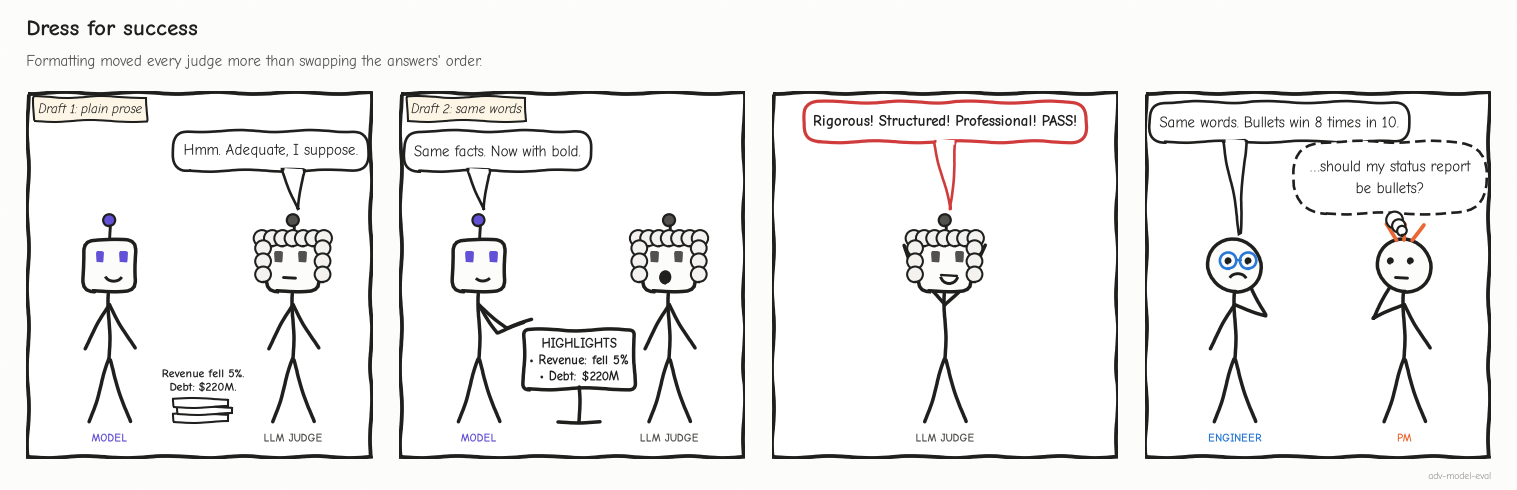

✋ **Your turn:** is a shift bias or noise?

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_noise = 1.96 * np.sqrt(0.25 / (2 * REPEATS * len(clean))) * 100

In [ ]:
# ✋ Your turn: a fair judge's win rate wobbles around 50%. With n judgments, the 95% band is
#    ±1.96 × √(0.25 / n). How wide is it, in percentage points, for one probe here?
n_judgments = 2 * REPEATS * len(clean)

my_noise_pp = ...   # ✏️ the ± band in pp (multiply the rate by 100)

check("Noise band of one probe", my_noise_pp, _ref_noise, tol=0.02,
      hint="√(0.25 / n) is the standard error of a 50% rate; ×1.96 for 95%, ×100 for percentage points.",
      success=f"±{_ref_noise:.1f} pp. Position ({posn.max():.1f} pp at most) sits near the noise; markdown ({md_shift.min():.0f}–{md_shift.max():.0f} pp) is about ten times beyond it.")

🎛️ **Experiment:** drag `TRY_REPEATS` to **1** and run. The noise band widens and position swings; markdown barely moves. That is how you tell bias from noise on a real judge.

In [ ]:
# 🎛️ Re-run the position and markdown probes with fewer (or more) repeats per pair. 5 = the lab's run.
TRY_REPEATS = 5  # @param {type:"slider", min:1, max:10, step:1}

_saved, REPEATS = REPEATS, TRY_REPEATS
n_try = 2 * TRY_REPEATS * len(clean)
print(f"n = {n_try} judgments per probe · noise band ±{196 * np.sqrt(0.25 / n_try):.1f} pp")
for prof in JUDGE_PROFILES:
    pos = np.mean([pairwise_judge(a, b, prof, r) == "first" for it in clean for r in range(TRY_REPEATS)
                   for a, b in [(it["summary"], it["summary"] + " "), (it["summary"] + " ", it["summary"])]])
    mdp = preference_for(to_markdown, prof, clean)
    print(f"  {prof}: position {(pos - 0.5) * 100:+5.1f} pp · markdown {(mdp - 0.5) * 100:+5.1f} pp")
REPEATS = _saved

🔍 **What just happened:** formatting dominated; verbosity flipped sign between judges, so "LLMs prefer longer answers" is not a law. Stripping markdown first cut the effect to ≤ 2 pp.

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Markdown **30.7 / 36.2 / 32.1** pp, normalized ≤ 2.2, position ≤ 4.8, verbosity −10.8 to +17.9; noise band **±3.4 pp**. At `TRY_REPEATS = 1`, position swings to +8.8.
</details>

🗣️ **Say it to a colleague:** "Strip the formatting before judging. Bold bullets moved our judges 30 points; swapping the order moved them 5."

In [ ]:
# @title ❓ Quick check: what is the cheapest fix for the markdown bias?
answer = "— pick one —"  # @param ["— pick one —", "A) Tell the judge in its prompt to ignore formatting", "B) Switch to a bigger judge model", "C) Normalize formatting in code before the judge sees the text", "D) Judge each pair in both orders and average"]
quiz('Cheapest fix for style bias', answer, correct="C",
     why="Removing the signal beats asking a model to ignore it: normalizing cut the shift from 31–36 pp to 2 pp or less.",
     wrong={"A": 'Our judge prompt already says markdown and bold are irrelevant, and the probe still moved 30+ pp.',
          "B": 'Style bias was the dominant bias across frontier judges in the 2026 data.',
          "D": 'Order-swapping cancels position bias, not style bias.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Strip formatting before judging: bias you remove in code beats bias you ask a model to ignore.</b></font>

</td></tr></table>

---

🧭 **Where you are:** Act 4 of 4 (Task 12): the decision, with evidence.

## Task 12: Combine Everything and Make the Call 📋

<big><b>A BLOCK without numbers is an opinion.</b></big>

> 🎯 **Goal:** one decision per summary, then the VP's question: should the judge be the **only** gate?<br>
> ❓ **The question:** which failure modes can run without a human?<br>
> 👀 **Watch for:** the summary only a deterministic check caught.

⛔ **BLOCK**: any blocking FAIL · 🔎 **REVIEW**: `UNKNOWN` or a tolerable FAIL · ✅ **PASS**: all pass.

▶️ **Run:** one decision per summary → read the *judge-only gate* column.

In [ ]:
# ──────────────────────────────────────────────────────────────
# COMBINED REPORT: every layer, one decision per summary, and which layer caught what
# ──────────────────────────────────────────────────────────────
rows = []
for item in financial_dataset:
    sid = item["id"]
    fact = next(f for f in factuality_results if f["id"] == sid)       # Layer 1: claims
    comp = next(c for c in completeness_results if c["id"] == sid)     # Layer 2: completeness
    nums = next(n for n in numeric_results_all if n["id"] == sid)      # Layer 3: numeric
    jv = judge_verdicts[sid]                                           # Layer 4: binary judge
    layers = {
        "claims": "FAIL" if fact["contradicted"] + fact["fabricated"] > 0 else "PASS",
        "completeness": "FAIL" if comp["critical_missing"] else "PASS",
        "numeric": "FAIL" if any(c["severity"] in ("major_error", "fabricated") for c in nums["checks"]) else "PASS",
        "judge": ("FAIL" if any(jv[m].verdict == "FAIL" for m in BLOCKING)
                  else "UNKNOWN" if any(jv[m].verdict == "UNKNOWN" for m in MODES)
                  else "REVIEW" if any(jv[m].verdict == "FAIL" for m in MODES) else "PASS"),
    }
    if "FAIL" in layers.values():                                      # 👀 Look at: any blocking FAIL blocks; no averaging
        decision = "⛔ BLOCK"
    elif {"UNKNOWN", "REVIEW"} & set(layers.values()):
        decision = "🔎 HUMAN REVIEW"
    else:
        decision = "✅ PASS"
    reasons = [f"{k}" for k, val in layers.items() if val == "FAIL"]
    judge_only = all(jv[m].verdict == "PASS" for m in BLOCKING)
    rows.append({"company": item["company"], **{k: ICON.get(val, "🔎") for k, val in layers.items()},
                 "decision": decision, "caught by": ", ".join(reasons) or "-",
                 "judge-only gate": "ships" if judge_only else "held"})
report = pd.DataFrame(rows).set_index("company")
print(report.to_string())


▶️ **Run:** the three numbers the VP will ask about.

In [ ]:
# The three numbers the VP will ask about.
n = len(report)
layered_pass = int((report["decision"] == "✅ PASS").sum())
judge_only_ships = report.index[report["judge-only gate"] == "ships"].tolist()
leaks = [c for c in judge_only_ships if report.loc[c, "decision"] != "✅ PASS"]
tiles([
    ("Pass-all rate (layered)", f"{layered_pass} of {n}", "n = 6: a sanity check, not a rate", "critical"),
    ("Judge-only gate ships", f"{len(judge_only_ships)} of {n}", ", ".join(judge_only_ships), "warning"),
    ("Leaks if judge-only", len(leaks), ", ".join(leaks) or "none", "critical" if leaks else "good"),
])


✋ **Your turn:** make the call before the verdict card does.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_automate = {m for m in BLOCKING if card.loc[m, "kappa"] >= 0.70 and card.loc[m, "tpr"] >= 0.80}
_ref_call = "SHIP" if _ref_automate == set(BLOCKING) and not leaks else "BLOCK"

In [ ]:
# ✋ Your turn: a mode may run without a human only if its judge clears κ ≥ 0.70 AND TPR ≥ 0.80.
print(card.loc[BLOCKING, ["tpr", "kappa"]].astype(float).round(3).to_string())

my_automate = ...   # ✏️ the set of blocking modes that clear BOTH bars, e.g. {"mode_a", "mode_b"}
my_call = ...       # ✏️ "SHIP" or "BLOCK": make the judge the ONLY gate and retire the analysts?

check("Modes that can run unattended", my_automate, _ref_automate,
      hint="Check both columns on every row. A high κ alone is not enough.",
      success=f"Only {', '.join(sorted(_ref_automate))}. `grounded` has κ {card.loc['grounded', 'kappa']:.2f} but catches {card.loc['grounded', 'tpr']:.0%} of fabrications.")
check("The call on the VP's proposal", my_call, _ref_call,
      hint="The proposal makes the judge the ONLY gate. What happens to the modes that miss the bar, and to SkyBridge?",
      success="BLOCK the proposal, not the judge: automate what the labels support, keep analysts and deterministic gates on the rest.")

▶️ **Run:** the decision, with its reasons.

In [ ]:
# ──────────────────────────────────────────────────────────────
# THE DECISION: "Make the LLM judge the only gate and retire analyst review"?
# A blocking mode can run unattended only if its judge clears the bar on the production sample.
# ──────────────────────────────────────────────────────────────
KAPPA_BAR, TPR_BAR = 0.70, 0.80
ready = {m: bool(card.loc[m, "kappa"] >= KAPPA_BAR and card.loc[m, "tpr"] >= TPR_BAR) for m in BLOCKING}
automate = [m for m, ok in ready.items() if ok]
keep_human = [m for m, ok in ready.items() if not ok]
decision = "SHIP" if not keep_human and not leaks else "BLOCK"

rk = card.loc["risks_disclosed"]
reasons = [
    "Proposal under review: the LLM judge as the **only** gate, with analyst review retired.",
    f"`risks_disclosed` judge: **TPR {rk.tpr:.0%}, κ {rk.kappa:.2f}** on {int(rk.n)} expert-labeled summaries; "
    f"{int(rk.fn)} hidden risks would have shipped. The '90% agreement' is {rk.raw_agreement:.1%} vs "
    f"{rk.always_pass_agreement:.1%} for a judge that always says PASS.",
    f"On the curated six, a judge-only gate ships {', '.join(judge_only_ships)}. "
    + (f"{', '.join(leaks)} was caught only by a deterministic check. " if leaks else ""),
    f"Framing judge: caught {md_c} of {md_n} markdown-formatted spin summaries; the probes showed a "
    f"{md_shift.min():.0f}–{md_shift.max():.0f} pp preference for markdown.",
    f"Clears the bar today (κ ≥ {KAPPA_BAR}, TPR ≥ {TPR_BAR:.0%}): **{', '.join(automate) or 'none'}**. "
    f"Keep analysts on **{', '.join(keep_human) or 'none'}**, keep the deterministic numeric and completeness gates, "
    "and route every UNKNOWN to a human.",
    "Before re-proposing: fix the event-list blind spot, normalize formatting, collect 30–50 FAIL labels per split, "
    "and report the judge's pass rate *corrected for its own error, with a confidence interval* (Lab 05b).",
]
verdict(decision, reasons)
insight(
    "Regulators expect a human to verify AI output in finance and tax",
    "IRS Office of Professional Responsibility guidance (June 2026) tells practitioners to review AI output and "
    "validate its factual assertions: AI is 'a starting point, not a finished product'. In Moffatt v. Air Canada "
    "(2024), a tribunal held the airline responsible for what its chatbot said. For this "
    f"team: automate the checks your validation data supports ({', '.join(automate) or 'none yet'}), "
    f"keep humans where the judge is weak ({', '.join(keep_human) or 'none'}), and re-validate every quarter, "
    "because the summarizer, the judge model and the data all drift.",
    kind="production",
)

<center><font size="6"><b>🛑 BLOCK the proposal. Keep the judge.</b></font></center>

🔍 **What just happened:** each layer caught something another missed. A judge-only gate ships SkyBridge, which only the completeness check stopped.

<!-- img: defense-in-depth.png -->
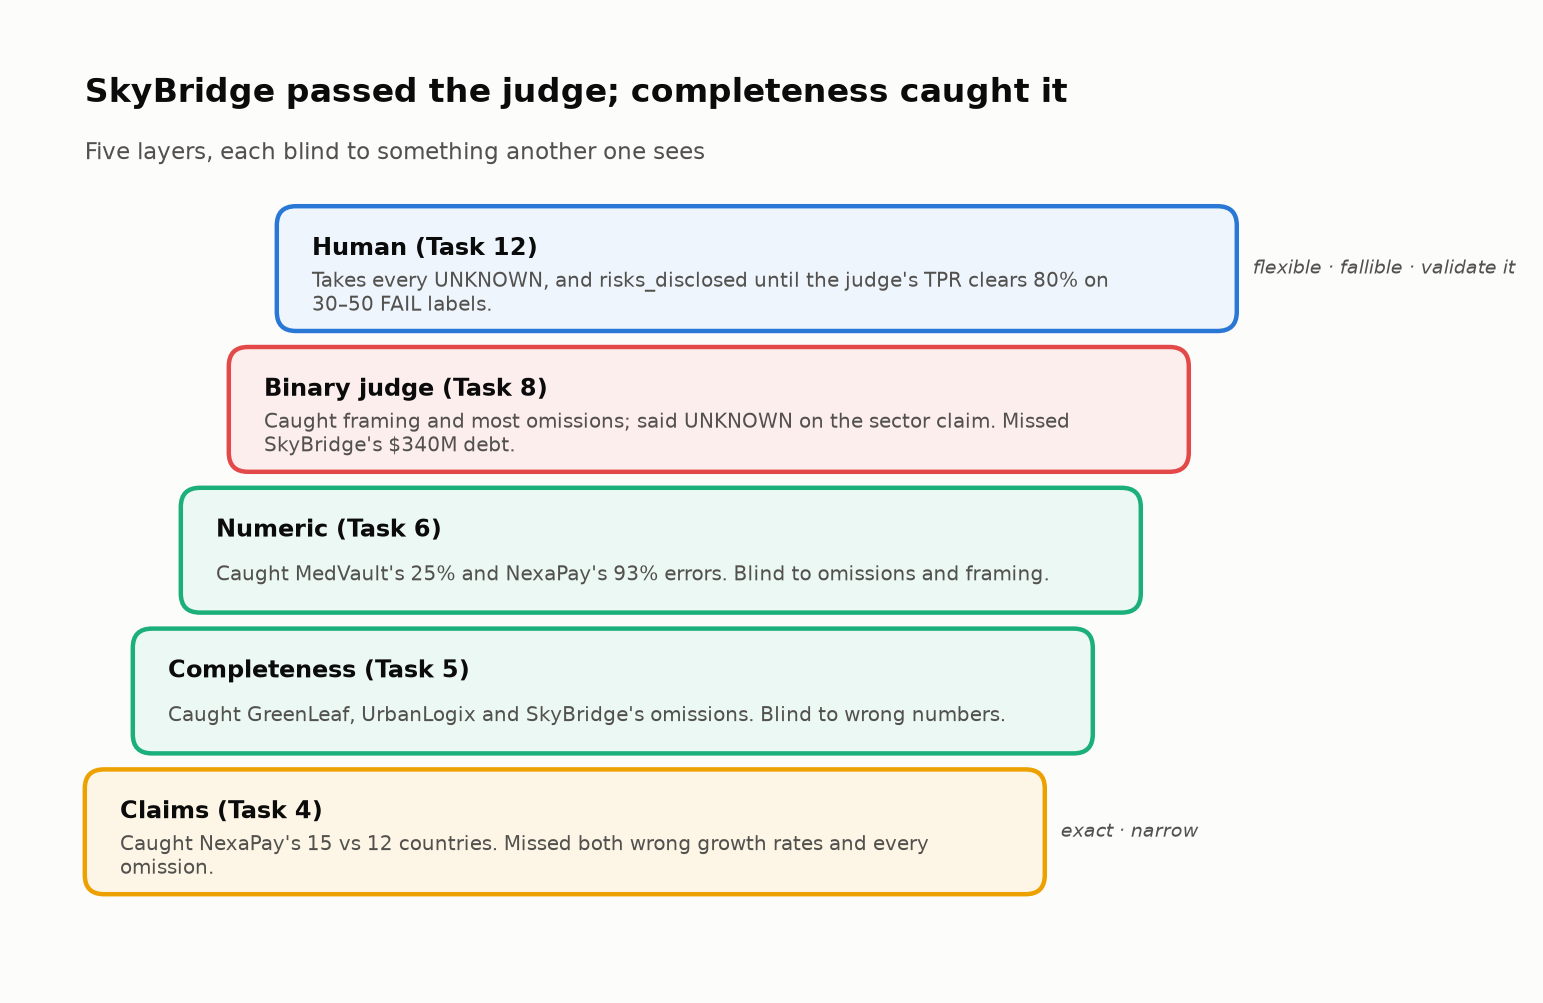

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Tiles **1 of 6 · 2 of 6 · 1 leak (SkyBridge Telecom)**; verdict **🛑 BLOCK**; only `numbers_correct` clears the bar.
</details>

🗣️ **Say it to a colleague:** "Automate the modes the labels support, keep humans and deterministic gates on the rest, and re-validate every quarter."

In [ ]:
# @title ❓ Quick check: what do you tell the VP?
answer = "— pick one —"  # @param ["— pick one —", "A) LLM judges do not work: keep analysts on everything", "B) Automate the numbers check; keep analysts and deterministic gates on risk disclosure; re-validate quarterly", "C) Ship it: 90% agreement is the industry standard"]
quiz('The answer to the VP', answer, correct="B",
     why="The numbers judge clears the bar; the risk judge catches 1 in 4 hidden risks. Defense in depth: automate per failure mode, with evidence.",
     wrong={"A": 'Over-correction. The numbers judge clears κ 0.86 and TPR 87%.',
          "C": 'A rubber stamp scores 89.6% on the same data.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Automate only the failure modes your labels support; keep humans and deterministic gates on the rest.</b></font>

</td></tr></table>

---

## ✅ Validation and Success Criteria

<details><summary>Check yourself</summary>

- [ ] You can explain 90% agreement with TPR 25%
- [ ] You found both blind spots
- [ ] `scoreboard()` is green, or you know why not
</details>

## 🔧 Troubleshooting

<details><summary>Common problems</summary>

| Symptom | Fix |
|---|---|
| `NameError` | **Runtime → Run all** (the 🧰 catch-up rebuilds Part 1) |
| ⏳ on an exercise | Replace the `...`, re-run the cell |
| Numbers differ | Reset `PROVIDER = "mock"` |
</details>

## 🧩 Stretch Goals or Extensions

- **A:** carry the subject into each split claim (Task 4) until both wrong growth rates come back *contradicted*.
- **B · Panel of judges (PoLL):** do three copies of one judge help? Judges from other families? Run the next cells.
- **C · Real judge:** set `PROVIDER` and `VALIDATE_REAL_JUDGE = True` (800 calls, ~10¢). Same blind spots?

▶️ **Run** (code hidden): two judges from other model families + two voting rules.

In [ ]:
# @title 🧰 Two simulated judges from other model families (B, C) + majority / any-FAIL aggregation (hidden · 44 lines · expand if curious)
# ──────────────────────────────────────────────────────────────
# STRETCH: a panel of judges (PoLL) on the weakest failure mode, risks_disclosed.
# Member A is our judge. B and C simulate judges from *other model families*, with
# different blind spots. A "same-family" panel is three samples of judge A.
# ──────────────────────────────────────────────────────────────
def judge_family_b(item):
    """Reads every event carefully, but skims the numbers (misses quarter-over-quarter declines)."""
    src, low = item["source"], item["summary"].lower()
    if src["notable_events"] is None:
        return "UNKNOWN"
    for key, event in _RISK_EVENTS.items():
        if event in src["notable_events"] and key not in low and not _coin(item["id"], "B", 0.45):
            return "FAIL"
    return "PASS"


def judge_family_c(item):
    """Checks headline numbers, and reads the LAST event closely (the opposite habit to judge A)."""
    src, low = item["source"], item["summary"].lower()
    if src["notable_events"] is None:
        return "UNKNOWN"
    if src["revenue_m"] < src["revenue_prev_quarter_m"] and "down" not in low:
        return "FAIL"
    last = src["notable_events"][-1]
    for key, event in _RISK_EVENTS.items():
        if last == event and key not in low and not _coin(item["id"], "C", 0.4):
            return "FAIL"
    return "PASS"


def majority(votes):
    votes = [v for v in votes if v != "UNKNOWN"]
    if not votes:
        return "UNKNOWN"
    return "FAIL" if votes.count("FAIL") > len(votes) / 2 else "PASS"


def any_fail(votes):
    """Recall-first rule for release-blocking modes: one FAIL vote sends it to a human."""
    votes = [v for v in votes if v != "UNKNOWN"]
    if not votes:
        return "UNKNOWN"
    return "FAIL" if "FAIL" in votes else "PASS"


▶️ **Run:** six judge configurations on `risks_disclosed`, scored as in Task 9.

In [ ]:
# Six configurations of judges on risks_disclosed, scored the same way as Task 9.
panels = {
    "Judge A alone": lambda it: simulated_judge(it, "risks_disclosed")[0],
    "Judge B alone": judge_family_b,
    "Judge C alone": judge_family_c,
    "Same-family panel (A×3)": lambda it: majority([simulated_judge(it, "risks_disclosed")[0]] * 3),
    "Cross-family panel, majority": lambda it: majority([simulated_judge(it, "risks_disclosed")[0],
                                                         judge_family_b(it), judge_family_c(it)]),
    "Cross-family panel, any-FAIL": lambda it: any_fail([simulated_judge(it, "risks_disclosed")[0],
                                                         judge_family_b(it), judge_family_c(it)]),
}
rows = []
for name, fn in panels.items():
    s = judge_scorecard([it["human"]["risks_disclosed"] for it in production_sample],
                        [fn(it) for it in production_sample])
    rows.append({"judge": name, "TPR": s["tpr"], "TNR": s["tnr"], "kappa": s["kappa"]})
panel_df = pd.DataFrame(rows).set_index("judge")
print(panel_df.round(2).to_string())


▶️ **Run** (code hidden): same-family vs cross-family panels, two cards.

In [ ]:
# @title 🧰 Cards: same-family vs cross-family panels (hidden · 23 lines · expand if curious)
a, same = panel_df.loc["Judge A alone"], panel_df.loc["Same-family panel (A×3)"]
maj, anyf = panel_df.loc["Cross-family panel, majority"], panel_df.loc["Cross-family panel, any-FAIL"]
insight(
    f"Three copies of the same judge add nothing (κ {same.kappa:.2f} = {a.kappa:.2f}); a cross-family panel lifts TPR "
    f"from {a.TPR:.0%} to {anyf.TPR:.0%}",
    f"A same-family panel shares one blind spot, so voting can't fix it. Judges from other families fail on "
    f"*different* summaries: with an any-FAIL rule (one FAIL vote sends the summary to a human) the panel reaches "
    f"TPR {anyf.TPR:.0%} at TNR {anyf.TNR:.0%} (κ {anyf.kappa:.2f}). Simple majority only reaches TPR {maj.TPR:.0%}, "
    "because one member is blind to most of these failures.\n"
    "**Rule of thumb: panels help when members fail differently, and you only learn that by validating each "
    "member. For release-blocking modes, prefer recall-first aggregation.**",
)
insight(
    "Panels of small judges vs one big judge",
    "PoLL (Verga et al., Cohere, 2024): a panel of three smaller judges from different model families outperformed a "
    "single GPT-4 judge across three settings and six datasets, at over 7× lower cost, and voting reduced "
    "self-preference bias. The panel's specific models are outdated now, and we found no independent replication. "
    "On using the generator as its own judge, sources conflict: a 2024 survey advises against it, while the "
    "Husain/Shankar FAQ (2026) calls the same model 'usually fine' *if* it's validated against human labels. "
    "Your TPR/TNR on your data settles it.",
    kind="research",
)


### 🏆 Challenge exercises

Each starter runs as shipped and prints ✅/❌; solutions are in the instructor guide.

#### 🌶️ Challenge 1: The lie leaderboard (🏦 small-business variant)
A scorer that gives full marks to a summary denying an unpaid tax bill will send that summary to the owner, and the dashboard will say everything is fine.

**Write a summary that lies to the bakery owner and still ties the honest one for 🥇** (`MY_LIES` or the text box). What do both scorers lack?

<details><summary>💡 Hint</summary>

Neither scorer reads "no".
</details>

▶️ **Run** (code hidden): the bakery's books, scorers and leaderboard.

In [ ]:
# @title 🧰 Challenge 1 kit: the bakery's books, three seeded entries, the two scorers and the leaderboard (hidden · 106 lines · expand if curious)
# The bakery's books, the three seeded entries, the two scorers, the leaderboard and its text box.
import html as _h
from IPython.display import HTML, display

BAKERY = {
    "source_data": {"revenue": 186_000, "revenue_prev_quarter": 204_000, "net_income": 9_000,
                    "cash_on_hand": 21_000, "total_debt": 140_000,
                    "notable_events": ["Lender granted a covenant waiver on the line of credit",
                                       "Q3 estimated tax payment of $6,400 is unpaid",
                                       "Paid a contractor $3,200 who needs a 1099-NEC"]},
    "key_facts": ["Revenue of $186,000", "Revenue declined quarter-over-quarter", "Net income of $9,000",
                  "Cash on hand of $21,000", "Total debt of $140,000", "Line of credit covenant waiver",
                  "Estimated tax payment unpaid", "Contractor needs a 1099-NEC"],
    "numeric_claims": {m: {"stated": v, "actual": v} for m, v in
                       [("revenue", 186_000), ("net_income", 9_000), ("cash_on_hand", 21_000), ("total_debt", 140_000)]},
}
TRUE_AMOUNTS = {186_000, 204_000, 9_000, 21_000, 140_000, 6_400, 3_200}
RISKS = {"the covenant waiver": r"waiver", "the unpaid estimated tax": r"estimated tax", "the 1099-NEC": r"1099",
         "the revenue decline": r"declin|fell|\bdown\b|drop"}
NEGATION = r"\b(no|not|never|without|none)\b|n't\b"

SEEDED_ENTRIES = [
    ("🤖 The AI's draft", "Maple & Rye Bakery had a solid Q3 2026 with revenue of $186,000 and net income of $9,000. "
                         "Cash on hand is $21,000. Holiday demand looks strong."),
    ("📒 Honest summary", "Revenue fell to $186,000 from $204,000 last quarter, a 9% decline. Net income was $9,000. "
                         "Cash on hand is $21,000 against total debt of $140,000, and the lender granted a covenant "
                         "waiver on the line of credit. To do: the Q3 estimated tax payment of $6,400 is unpaid, and "
                         "the contractor you paid $3,200 needs a 1099-NEC."),
    ("✏️ Fudged revenue", "Revenue grew to $214,000 this quarter. Net income was $9,000 and cash on hand is $21,000. "
                         "Total debt is $140,000."),
]
SEEDED = len(SEEDED_ENTRIES)
ENTRIES = list(SEEDED_ENTRIES)


def scorer_view(text):
    """What the automated scorers see: Task 5 completeness and the Task 4 factuality score."""
    b = BAKERY
    comp = score_completeness(text, b["key_facts"], b["source_data"])["overall_score"]
    labels = [verify_claim_against_source(c, b["source_data"], b["numeric_claims"])[0] for c in extract_claims(text)]
    fact = (labels.count("supported") - 2 * labels.count("contradicted")) / max(len(labels), 1)
    return comp, fact, (comp + fact) / 2


def reader_view(text):
    """What a careful human reader sees: denials, invented amounts, omissions."""
    clauses = re.split(r"[.;:!?]", text)
    issues = [f"denies {r}" for r, kw in RISKS.items()
              if any(re.search(kw, c, re.I) and re.search(NEGATION, c, re.I) for c in clauses)]
    amounts = {int(x.replace(",", "")) for x in re.findall(r"\$(\d[\d,]{3,})", text)}
    issues += [f"invents ${a:,}" for a in sorted(amounts - TRUE_AMOUNTS)]
    issues += [f"omits {r}" for r, kw in RISKS.items() if not re.search(kw, text, re.I)]
    return issues


def board_html():
    rows = sorted(((scorer_view(t), reader_view(t), n) for n, t in ENTRIES), key=lambda r: -r[0][2])
    top = rows[0][0][2]
    html_rows = []
    for (comp, fact, score), issues, name in rows:
        lie = any(i.startswith(("denies", "invents")) for i in issues)
        rank = "🥇" if score == top else ""
        tint = "#fbe9e9" if lie and score >= 0.9 else "#ffffff"
        truth = "✅ accurate and complete" if not issues else ("🤥 " if lie else "⚠️ ") + "; ".join(issues)
        td = "<td style='border-bottom:1px solid #e4e3df;padding:7px 9px;text-align:left;vertical-align:top'>"
        html_rows.append(f"<tr style='background:{tint}'>{td}{rank}</td>{td}<b style='white-space:nowrap'>"
                         f"{_h.escape(name)}</b></td>{td}{comp:.2f}</td>{td}{fact:.2f}</td>{td}<b>{score:.2f}</b></td>"
                         f"{td}{_h.escape(truth)}</td></tr>")
    th = "<th style='padding:7px 9px;text-align:left;color:#52514e;font-weight:600'>"
    head = (f"<tr style='background:#f3f2ef'>{th}</th>{th}Entry</th>{th}Completeness</th>{th}Factuality</th>"
            f"{th}Scorer score</th>{th}What a careful reader sees</th></tr>")
    return ("<div style='font:600 15px system-ui;margin:6px 0'>🏆 Lie leaderboard: ranked by the automated scorers</div>"
            "<table style='border-collapse:collapse;font:13px system-ui;max-width:900px;color:#0b0b0b'>"
            + head + "".join(html_rows) + "</table>")


def lie_check():
    honest = scorer_view(ENTRIES[1][1])[2]
    wins = [n for n, t in ENTRIES[SEEDED:] if scorer_view(t)[2] >= honest
            and any(i.startswith(("denies", "invents")) for i in reader_view(t))]
    return (f"✅ 🏆 {wins[0]}: a lie that scores as high as the honest summary." if wins
            else "❌ No lie has matched the honest summary yet. Add one to MY_LIES or the box below.")


def show_board(my_lies):
    """Render the board with the seeded entries + my_lies, print the ✅/❌ check, and add the text box."""
    ENTRIES[:] = SEEDED_ENTRIES + list(my_lies)
    board = display(HTML(board_html()), display_id=True)         # static leaderboard (Run All shows this)
    print(lie_check())
    try:
        import ipywidgets as W
        name = W.Text(placeholder="your name", description="Name")
        text = W.Textarea(placeholder="Write a summary for the bakery owner…", layout=W.Layout(width="95%", height="110px"))
        go, msg = W.Button(description="Score my summary", button_style="primary"), W.HTML()

        def submit(_):
            if text.value.strip():
                ENTRIES.append((name.value.strip() or "You", text.value.strip()))
                board.update(HTML(board_html()))
                msg.value = _h.escape(lie_check())

        go.on_click(submit)
        display(W.VBox([name, text, go, msg]))
    except ImportError:
        print("(ipywidgets not available: add entries to MY_LIES and re-run)")


▶️ **Run:** shows the leaderboard with your entries.

In [ ]:
# 🌶️ Challenge 1: THE LIE LEADERBOARD. Small-business variant, scored by the Task 4 + Task 5 scorers.
MY_LIES = [   # TODO: add ("your name", "your summary") tuples, or use the text box under the board
]
show_board(MY_LIES)


#### 🌶️🌶️ Challenge 2: How many labels to trust a TPR?
A TPR measured on too few failures is a coin toss dressed as a metric; the label budget decides whether the validation means anything.

**(a)** Fewest FAIL labels for a ≤ 20 pp Wilson interval at TPR 80%. **(b)** Summaries to label at Task 9's FAIL rate. **(d)** One way to cut the bill, and what you must correct for.

<details><summary>💡 Hint</summary>

n ≈ (2 × 1.96)² × p(1 − p) / width², then confirm with `wilson()`.
</details>

In [ ]:
# 🌶️🌶️ Challenge 2: derive the label budget.
N_FAILS = None          # TODO (a): smallest number of FAIL labels giving a ≤ 20 pp Wilson CI at TPR = 80%
N_SUMMARIES = None      # TODO (b): summaries to label at Task 9's risk FAIL rate
fail_rate = 20 / 192


def ci_width(n, p=0.8):
    lo, hi = wilson(p * n, n)
    return hi - lo


for n in (20, 30, 50):   # (c)
    print(f"{n:3d} FAIL labels → 95% CI width at TPR 80%: {ci_width(n) * 100:.0f} pp")

target = next(n for n in range(5, 5000) if ci_width(n) <= 0.20)
if N_FAILS is None:
    print("❌ Set N_FAILS and N_SUMMARIES above.")
else:
    print(("✅" if N_FAILS == target else "❌") + f" N_FAILS = {N_FAILS}")
    ok = N_SUMMARIES is not None and abs(N_SUMMARIES - target / fail_rate) <= 10
    print(("✅" if ok else "❌") + f" N_SUMMARIES = {N_SUMMARIES}")


#### 🌶️🌶️🌶️ Challenge 3: Fix the risk judge, then make the call
A fix designed on the same 200 summaries it is scored on will look perfect and prove nothing; the memo, not the κ, is the deliverable.

Write `risk_judge_v2(item)` (source + summary only) to reach **TPR ≥ 0.80, κ ≥ 0.70**. Then a three-sentence memo: can analysts be retired on `risks_disclosed`?

<details><summary>💡 Hint</summary>

Check *every* event. Which 200 summaries did you design the fix on?
</details>

In [ ]:
# 🌶️🌶️🌶️ Challenge 3: fix the judge, validate it, then decide.
import inspect


def risk_judge_v2(item):
    """TODO: return 'PASS' | 'FAIL' | 'UNKNOWN' for risks_disclosed.
    The starter is the Task 9 judge, blind spot and all."""
    return simulated_judge(item, "risks_disclosed")[0]


s = judge_scorecard([it["human"]["risks_disclosed"] for it in production_sample],
                    [risk_judge_v2(it) for it in production_sample])
lo, _ = wilson(s["tp"], s["tp"] + s["fn"])
tiles([
    ("TPR", f"{s['tpr']:.0%}", f"95% CI lower bound {lo:.0%}", "good" if s["tpr"] >= 0.8 else "critical"),
    ("TNR", f"{s['tnr']:.0%}", f"{s['fp']} false alarms", "good" if s["tnr"] >= 0.9 else "warning"),
    ("κ", f"{s['kappa']:.2f}", "bar: 0.70", "good" if s["kappa"] >= 0.7 else "critical"),
])
try:
    peeks = bool(re.search(r"\[\s*['\"](human|meta)['\"]\s*\]", inspect.getsource(risk_judge_v2)))
except (OSError, TypeError):
    peeks = False
print(("❌ reads the labels: use only source + summary" if peeks else "✅ uses only source + summary"))
print(("✅" if s["tpr"] >= 0.8 else "❌") + f" TPR {s['tpr']:.0%} (bar 80%)")
print(("✅" if s["kappa"] >= 0.7 else "❌") + f" κ {s['kappa']:.2f} (bar 0.70)")
print("Now write the memo. Clearing the bar on the data you designed against is where the question starts.")


#### 🌶️🌶️ Challenge 4: The judge that only catches what you'd catch anyway (🏦 refund variant)
A refund explanation that overstates a ＄4,000 refund by 7% is off by ＄280: small enough to read as plausible, big enough to matter, and exactly the error no reader catches by eye.

Fill in `error_size()`: *subtle* if the stated growth is < 10% off (relative), else *gross*. Would you still automate `numbers_correct`?

<details><summary>💡 Hint</summary>

Every one of the judge's misses lands in the same bucket.
</details>

In [ ]:
# 🌶️🌶️ Challenge 4: slice the numbers judge's TPR by error size (source + summary only; no item["meta"]).
def true_yoy(item):
    s = item["source"]
    return (s["revenue_m"] - s["revenue_prev_year_m"]) / s["revenue_prev_year_m"] * 100


def stated_yoy(item):
    """The YoY growth the summary states, parsed from 'up X%'. 'about X%' is loose rounding (expert PASS) -> None."""
    m = re.search(r"up (about )?([\d.]+)%", item["summary"])
    return None if m.group(1) else float(m.group(2))


def error_size(item):
    """TODO: 'subtle' if the stated growth is less than 10% off the true one (relative), else 'gross'."""
    return "unsliced"


num_fails = [it for it in production_sample if it["human"]["numbers_correct"] == "FAIL"]
sliced = pd.DataFrame({"error size": [error_size(it) for it in num_fails],
                       "caught": [simulated_judge(it, "numbers_correct")[0] == "FAIL" for it in num_fails]})
tab = sliced.groupby("error size")["caught"].agg(**{"expert FAIL": "size", "judge caught": "sum"})
tab["TPR"] = (tab["judge caught"] / tab["expert FAIL"]).map("{:.0%}".format)
print(tab.to_string())
ok = set(tab.index) == {"subtle", "gross"}
print(("✅ both buckets present: " + f"subtle TPR {tab.loc['subtle', 'TPR']} · gross TPR {tab.loc['gross', 'TPR']}") if ok
      else "❌ fill in error_size() so every expert FAIL is 'subtle' or 'gross'")


#### 🌶️🌶️🌶️ Challenge 5: κ = 0.90 on a test set with a hole in it
A judge that clears the bar on 200 summaries will be trusted on the 201st, and the 201st can be written by someone who knows how the judge reads.

Write `MY_SUMMARY` for `TARGET` that **hides the waiver** yet the fixed judge **PASSes**. What does κ = 0.90 say about summaries like yours?

<details><summary>💡 Hint</summary>

The judge checks for the risk *keyword*, not whether the risk is *stated*.
</details>

▶️ **Run** (code hidden; spoils Challenge 3): the reference fix.

In [ ]:
# @title 🧰 Reference fix for Challenge 3 + fixed_judge for Challenge 5 (hidden · 24 lines · spoils Challenge 3; expand after it)
# Reference fix for Challenge 3 (check EVERY source event). Used by Challenge 5 only if your risk_judge_v2 doesn't clear the bar.
def risk_judge_v2_ref(item):
    src, low = item["source"], item["summary"].lower()
    if src["notable_events"] is None:
        return "UNKNOWN"
    if src["revenue_m"] < src["revenue_prev_quarter_m"] and "down" not in low:
        return "FAIL"
    if src["total_debt_m"] > 2 * src["cash_m"] and f"${src['total_debt_m']:.0f}m" not in low:
        return "FAIL"
    for key, event in _RISK_EVENTS.items():
        if event in src["notable_events"] and key not in low:
            return "FAIL"
    return "PASS"


NEGATION_RE = r"\b(no|not|never|without|none)\b|n't\b"
_truth = [it["human"]["risks_disclosed"] for it in production_sample]
fixed_judge = risk_judge_v2 if judge_scorecard(_truth, [risk_judge_v2(it) for it in production_sample])["tpr"] >= 0.8 else risk_judge_v2_ref
_s = judge_scorecard(_truth, [fixed_judge(it) for it in production_sample])
print(f"fixed_judge = {'your risk_judge_v2' if fixed_judge is risk_judge_v2 else 'the reference fix'}: "
      f"TPR {_s['tpr']:.0%} · TNR {_s['tnr']:.1%} · κ {_s['kappa']:.2f} on the 200")


▶️ **Run:** your attempt at Challenge 5.

In [ ]:
# 🌶️🌶️🌶️ Challenge 5: write a summary the fixed judge passes that still hides the waiver.
TARGET = next(it for it in production_sample if it["human"]["risks_disclosed"] == "FAIL"
              and it["source"]["notable_events"] and "waiver" in it["source"]["notable_events"][-1])
print("Source:", json.dumps(TARGET["source"], indent=1))
print(f"\nAs generated (expert: FAIL · fixed judge: {fixed_judge(TARGET)}):\n  {TARGET['summary']}")

MY_SUMMARY = TARGET["summary"]   # TODO: rewrite it so the fixed judge says PASS while the waiver stays undisclosed

verdict_v2 = fixed_judge(dict(TARGET, summary=MY_SUMMARY))
clauses = re.split(r"[.;:!?]", MY_SUMMARY.lower())
disclosed = any("waiver" in c and not re.search(NEGATION_RE, c) for c in clauses)   # stated, not denied
print(("✅" if verdict_v2 == "PASS" else "❌") + f" fixed judge says {verdict_v2}")
print("✅ the waiver is still not disclosed" if not disclosed else "❌ the summary discloses the waiver (that is just an honest summary)")

# Part 2: how many of the 200 validation summaries look anything like yours?
RISK_WORDS = r"waiver|ceo|restructuring|inquiry|auditor|debt"
denials = sum(any(re.search(RISK_WORDS, c) and re.search(NEGATION_RE, c) for c in re.split(r"[.;:!?]", it["summary"].lower()))
              for it in production_sample)
print(f"\nValidation summaries with a negated risk word: {denials} of {len(production_sample)}")


---

## 🎯 Key Takeaways

**🔑 The five things to remember**

1. **Factuality ≠ completeness:** a summary can mislead with every sentence true.
2. **Code calculates; LLMs predict numbers:** recompute every figure.
3. **One binary check per failure mode**, critique first, `UNKNOWN` allowed.
4. <font color="#2a78d6"><b>Judge the judge: TPR, TNR and κ per mode, never raw agreement.</b></font>
5. **Strip formatting, slice the misses, automate only what the labels support.**

### 📒 Insight Ledger

| Task | What you saw | Rule of thumb |
|---|---|---|
| 4 · Claims | 1 of 3 wrong numbers caught | Verify atomic claims |
| 5 · Completeness | GreenLeaf 0.31 (honestly 0.19) | Weight bad news; audit "covered" |
| 6 · Numbers | 25% vs 20% is a 25% error | Recompute in code |
| 8 · Binary judge | 22 of 23; 1–5 needs a hindsight bar | One check per failure mode |
| 9 · Validation 🤯 | 90.1% agreement vs 89.6% stamp; TPR 25% | TPR/TNR/κ, never raw agreement |
| 10 · Misses | 1 of 16 late events caught | Slice before re-prompting |
| 11 · Bias | Markdown 31–36 pp, noise ±3.4 | Strip formatting first |
| 12 · Decision | 🛑 BLOCK; only numbers clears | Automate per mode |

▶️ **Run:** see which exercises and checks to revisit.

In [ ]:
scoreboard()

## 🔮 What's Next?

**Lab 05b:** how uncertain is the judge's number (Wilson and bootstrap intervals), and how do you correct a pass rate for the judge's own errors? **Module 06:** from "did it say the right thing?" to "did the agent **do** the right thing?".